# Bank Marketing Campaign: Predicting Term Deposit Subscriptions

A Portuguese bank ran phone campaigns to sell term deposits. Using the UCI Bank Marketing dataset (4,521 clients, 16 features), this notebook predicts which clients will subscribe so the bank can call the most promising ones first.

Steps:
1. Load the data and check quality
2. Exploratory analysis (demographic, financial, and campaign features)
3. Preprocessing: label encoding, undersampling to fix the 7.7:1 class imbalance, train/test split, scaling
4. Train and compare five classifiers, tracking each run with MLflow
5. Evaluate the best model (confusion matrix, ROC and precision-recall curves, feature importance)
6. Takeaways

## Load Data and Initial Overview

In [1]:
import warnings
import logging

warnings.filterwarnings("ignore")
logging.getLogger("mlflow").setLevel(logging.ERROR)

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# Load bank marketing data
bank_df = pd.read_csv("../data/bank.csv", sep=";")

df = bank_df.copy()

print("="*70)
print("DATASET OVERVIEW")
print("="*70)
print(f"Total Records: {len(df):,}")
print(f"Total Features: {len(df.columns)}")
print(f"\nFeatures: {list(df.columns)}")
print("\nFirst few rows:")
display(df.head())


DATASET OVERVIEW
Total Records: 4,521
Total Features: 17

Features: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

First few rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


## Data Quality Check

In [2]:
print("="*70)
print("DATA QUALITY ASSESSMENT")
print("="*70)

# Check data types
print("\n1. Data Types:")
print(df.dtypes)

# Check for missing values
print("\n2. Missing Values:")
missing = df.isnull().sum()
if missing.sum() == 0:
    print("No missing values.")
else:
    print(missing[missing > 0])

# Check for duplicates
duplicates = df.duplicated().sum()
print(f"\n3. Duplicate Rows: {duplicates}")

# Basic statistics
print("\n4. Numerical Features Summary:")
display(df.describe())


DATA QUALITY ASSESSMENT

1. Data Types:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

2. Missing Values:
No missing values.

3. Duplicate Rows: 0

4. Numerical Features Summary:


,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


## Target Variable Analysis

TARGET VARIABLE ANALYSIS

Response Distribution:
   no:  4,000 (88.48%)
  yes:    521 (11.52%)

Class Imbalance Ratio: 7.68:1


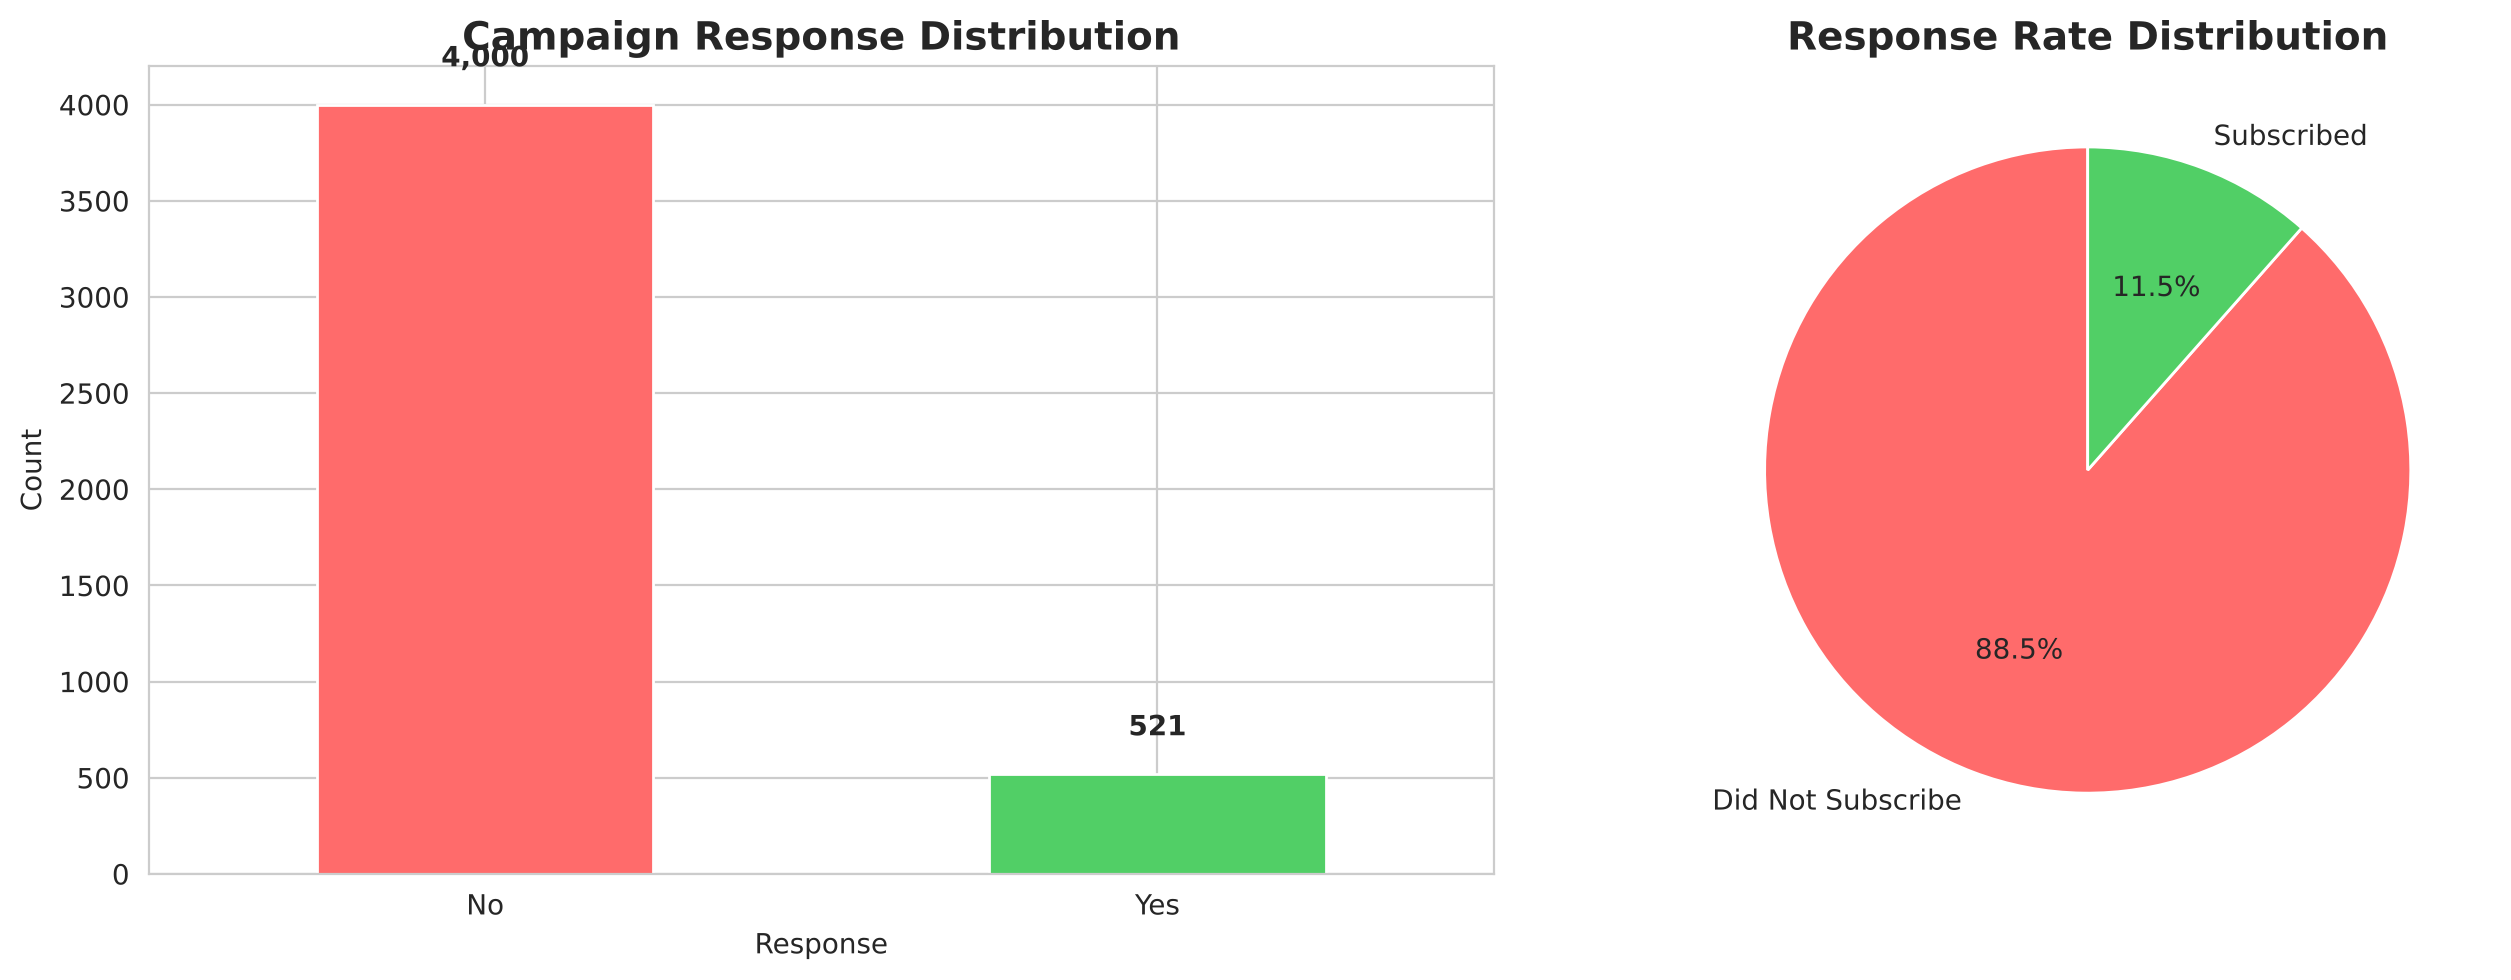


The classes are imbalanced; this is handled with undersampling during preprocessing.


In [3]:
print("="*70)
print("TARGET VARIABLE ANALYSIS")
print("="*70)

# Class distribution
target_counts = df['y'].value_counts()
target_pct = df['y'].value_counts(normalize=True) * 100

print("\nResponse Distribution:")
for val in ['no', 'yes']:
    print(f"  {val:>3}: {target_counts[val]:>6,} ({target_pct[val]:>5.2f}%)")

print(f"\nClass Imbalance Ratio: {target_counts['no'] / target_counts['yes']:.2f}:1")

# Visualize
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Count plot
target_counts.plot(kind='bar', ax=ax[0], color=['#ff6b6b', '#51cf66'])
ax[0].set_title('Campaign Response Distribution', fontsize=14, fontweight='bold')
ax[0].set_xlabel('Response')
ax[0].set_ylabel('Count')
ax[0].set_xticklabels(['No', 'Yes'], rotation=0)
for i, v in enumerate(target_counts):
    ax[0].text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')

# Pie chart
target_pct.plot(kind='pie', ax=ax[1], autopct='%1.1f%%', startangle=90,
                colors=['#ff6b6b', '#51cf66'], labels=['Did Not Subscribe', 'Subscribed'])
ax[1].set_ylabel('')
ax[1].set_title('Response Rate Distribution', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nThe classes are imbalanced; this is handled with undersampling during preprocessing.")


## Demographic Features Analysis

DEMOGRAPHIC FEATURES ANALYSIS



1. AGE:
   Range: 19 - 87 years
   Mean: 41.2 years
   Median: 39 years

2. JOB TYPES:
   Unique jobs: 12
   Most common: management (969)

3. MARITAL STATUS:
   married: 2,797 (61.9%)
   single: 1,196 (26.5%)
   divorced: 528 (11.7%)

4. EDUCATION:
   primary: 678 (15.0%)
   secondary: 2,306 (51.0%)
   tertiary: 1,350 (29.9%)
   unknown: 187 (4.1%)


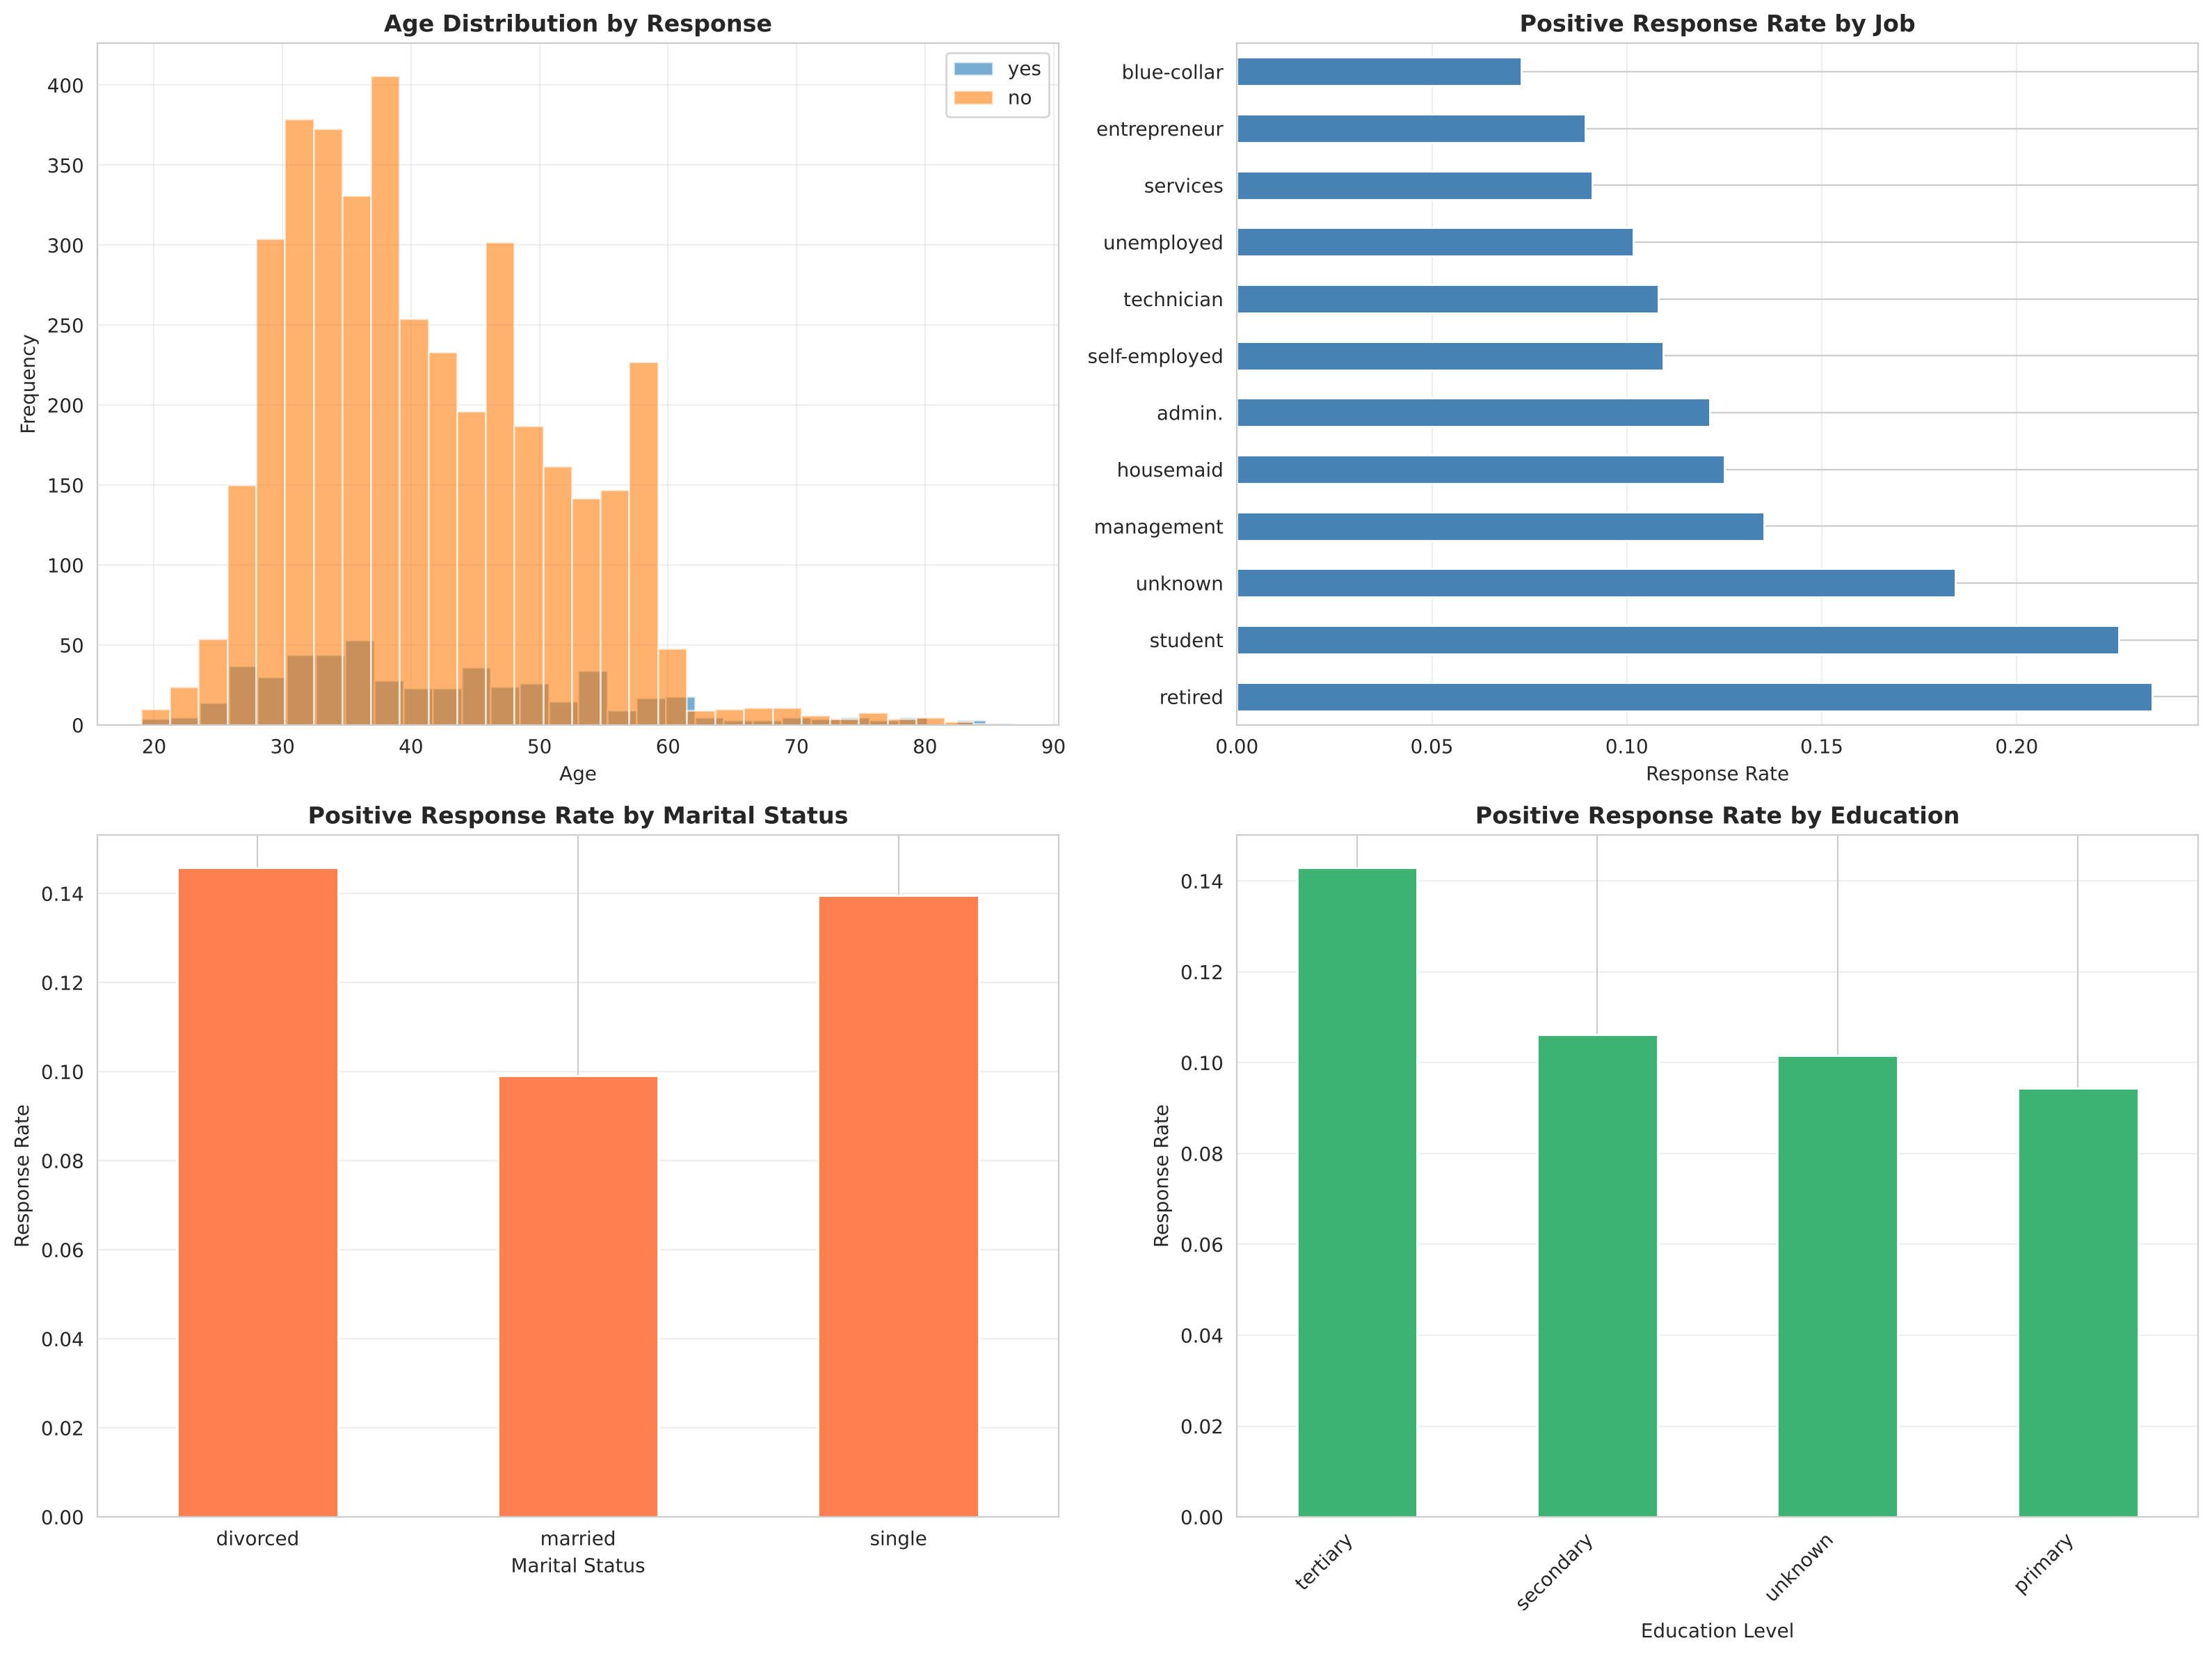

In [4]:
print("="*70)
print("DEMOGRAPHIC FEATURES ANALYSIS")
print("="*70)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Age Distribution
ax = axes[0, 0]
for resp in ['yes', 'no']:
    df[df['y'] == resp]['age'].hist(bins=30, alpha=0.6, label=resp, ax=ax)
ax.set_title('Age Distribution by Response', fontsize=12, fontweight='bold')
ax.set_xlabel('Age')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(alpha=0.3)

print(f"\n1. AGE:")
print(f"   Range: {df['age'].min()} - {df['age'].max()} years")
print(f"   Mean: {df['age'].mean():.1f} years")
print(f"   Median: {df['age'].median():.0f} years")

# 2. Job Distribution
ax = axes[0, 1]
job_response = df.groupby('job')['y'].value_counts(normalize=True).unstack().fillna(0)
job_response['yes'].sort_values(ascending=False).plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Positive Response Rate by Job', fontsize=12, fontweight='bold')
ax.set_xlabel('Response Rate')
ax.set_ylabel('')
ax.grid(alpha=0.3, axis='x')

print(f"\n2. JOB TYPES:")
print(f"   Unique jobs: {df['job'].nunique()}")
print(f"   Most common: {df['job'].value_counts().index[0]} ({df['job'].value_counts().values[0]:,})")

# 3. Marital Status
ax = axes[1, 0]
marital_response = df.groupby('marital')['y'].value_counts(normalize=True).unstack().fillna(0)
marital_response['yes'].plot(kind='bar', ax=ax, color='coral')
ax.set_title('Positive Response Rate by Marital Status', fontsize=12, fontweight='bold')
ax.set_xlabel('Marital Status')
ax.set_ylabel('Response Rate')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.grid(alpha=0.3, axis='y')

print(f"\n3. MARITAL STATUS:")
for status in df['marital'].unique():
    count = (df['marital'] == status).sum()
    pct = 100 * count / len(df)
    print(f"   {status}: {count:,} ({pct:.1f}%)")

# 4. Education
ax = axes[1, 1]
edu_response = df.groupby('education')['y'].value_counts(normalize=True).unstack().fillna(0)
edu_response['yes'].sort_values(ascending=False).plot(kind='bar', ax=ax, color='mediumseagreen')
ax.set_title('Positive Response Rate by Education', fontsize=12, fontweight='bold')
ax.set_xlabel('Education Level')
ax.set_ylabel('Response Rate')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.grid(alpha=0.3, axis='y')

print(f"\n4. EDUCATION:")
for edu in df['education'].unique():
    count = (df['education'] == edu).sum()
    pct = 100 * count / len(df)
    print(f"   {edu}: {count:,} ({pct:.1f}%)")

plt.tight_layout()
plt.show()


## Financial Features Analysis

FINANCIAL FEATURES ANALYSIS

1. ACCOUNT BALANCE:
   Mean: $1,423
   Median: $444
   Range: $-3,313 to $71,188
   Negative balances: 366 (8.1%)

2. HOUSING LOAN:
   no: 1,962 (43.4%)
   yes: 2,559 (56.6%)

3. PERSONAL LOAN:
   no: 3,830 (84.7%)
   yes: 691 (15.3%)

4. CREDIT DEFAULT:
   no: 4,445 (98.3%)
   yes: 76 (1.7%)


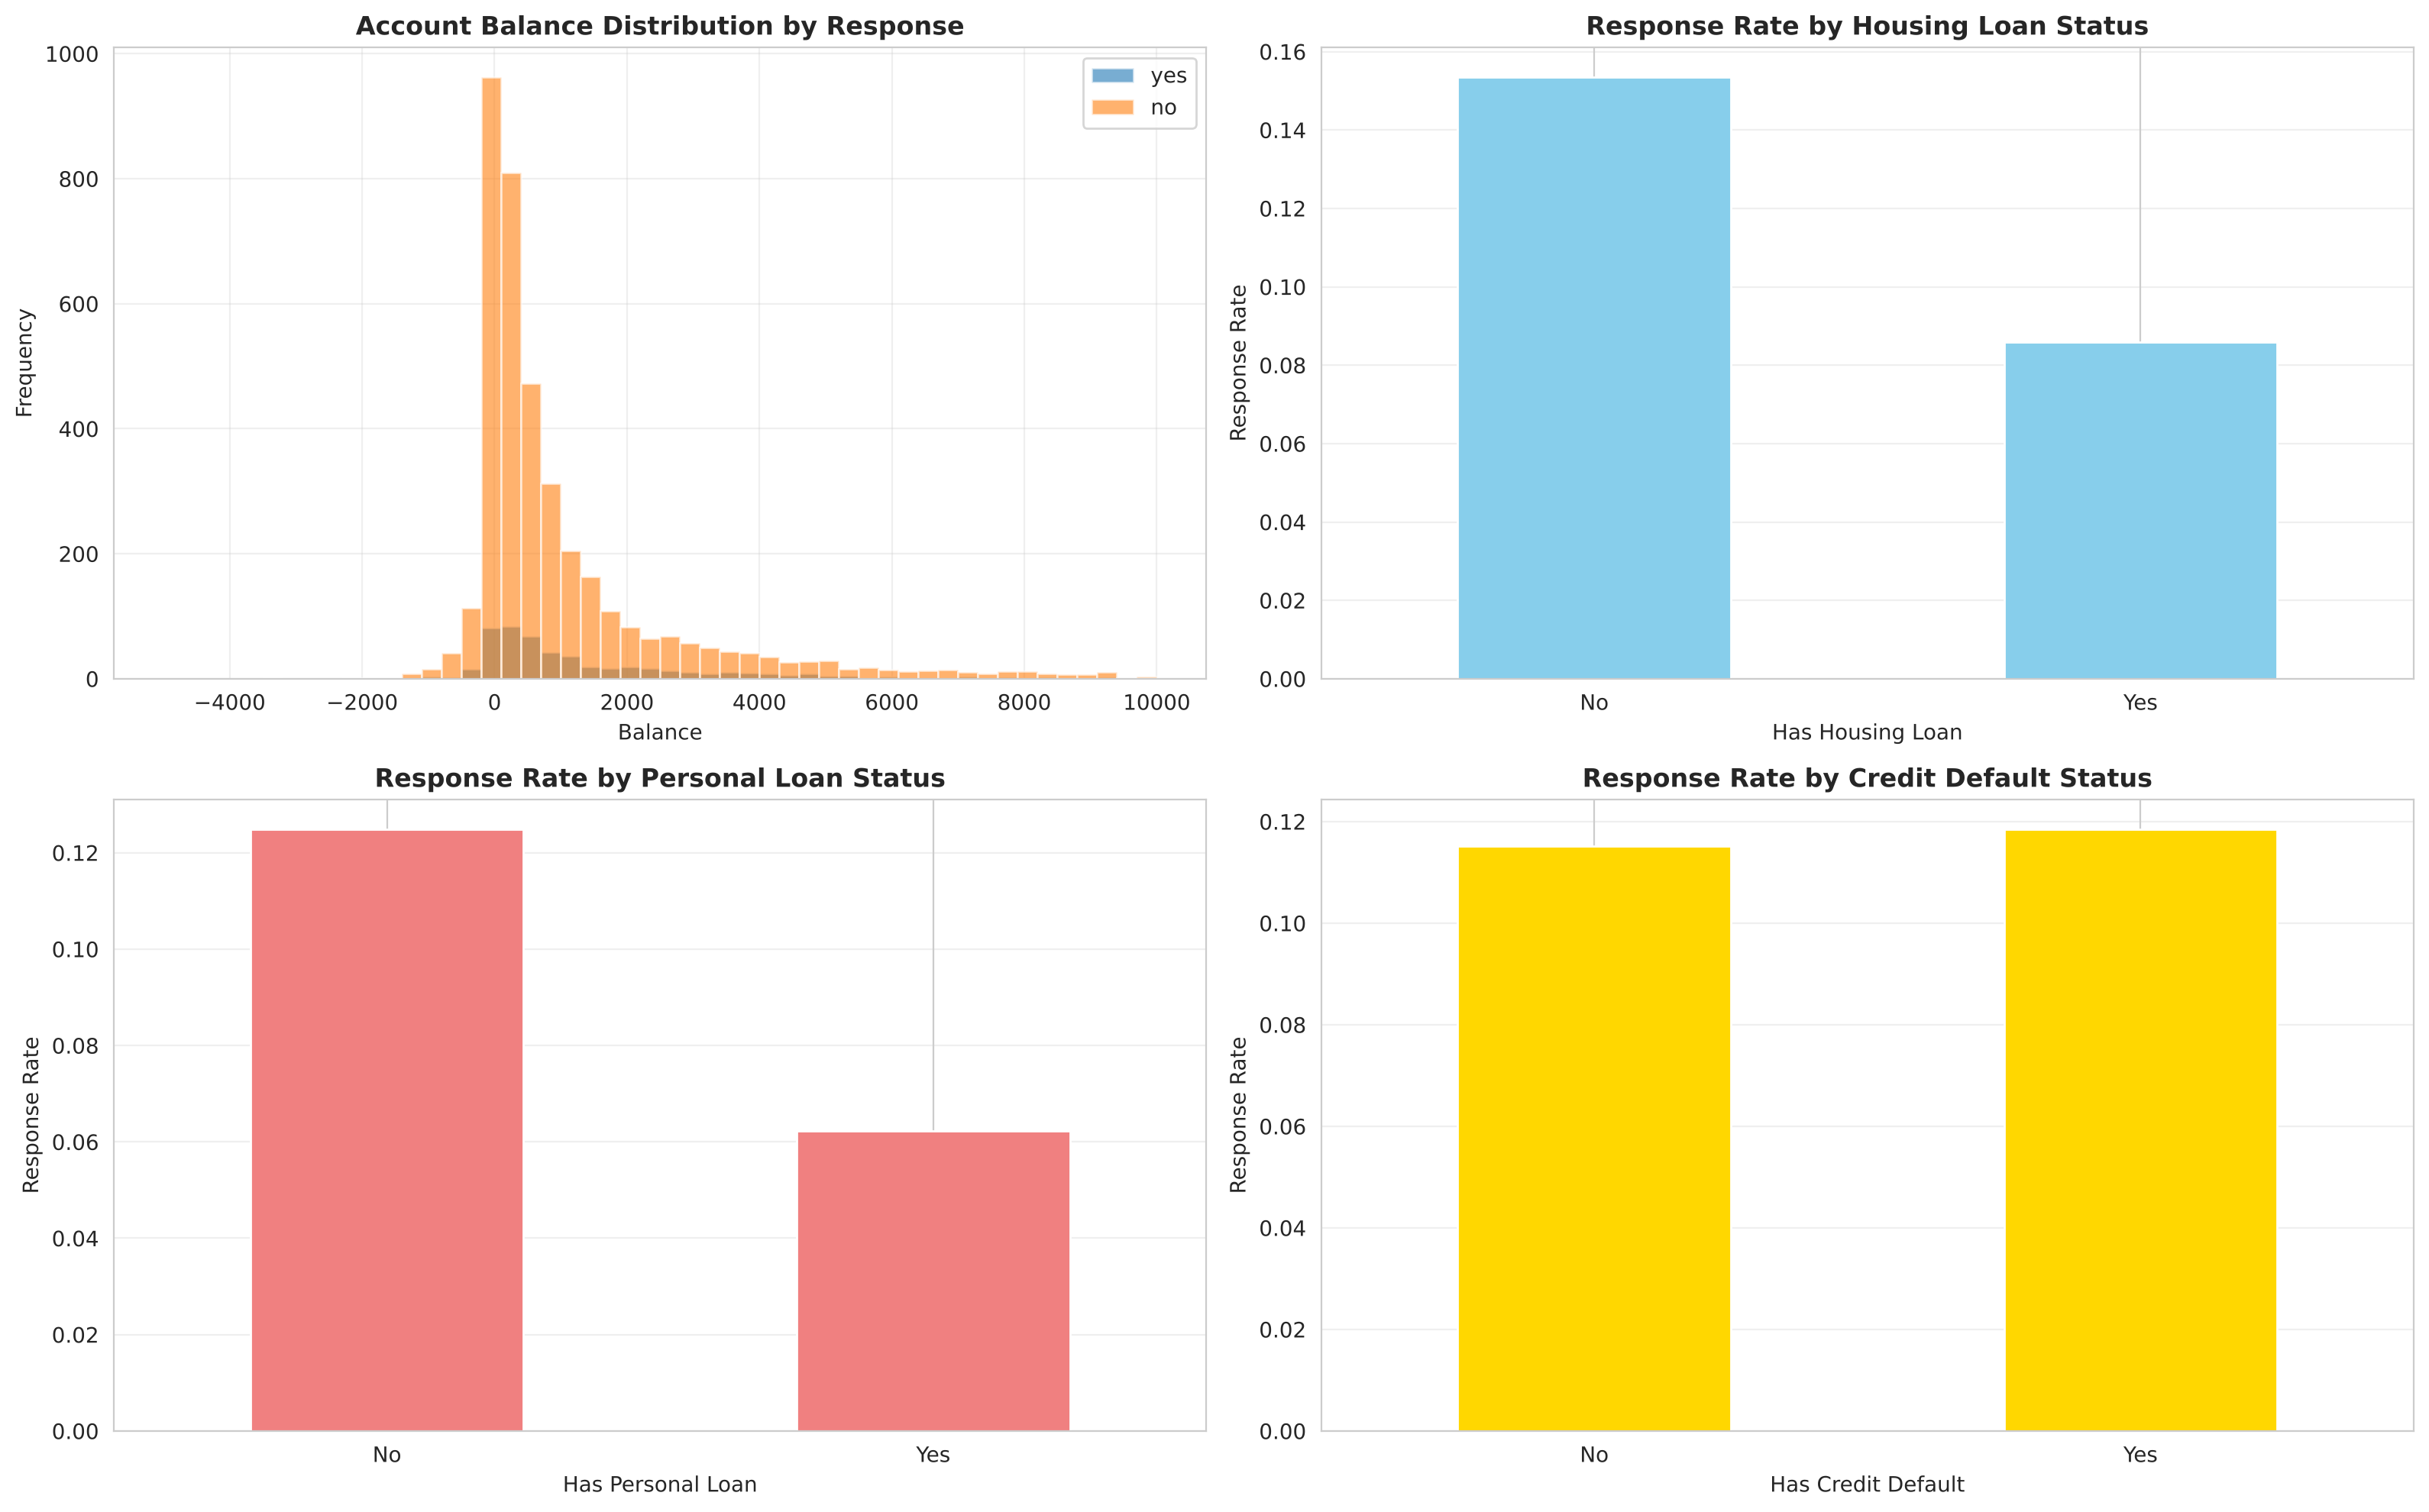

In [5]:
print("="*70)
print("FINANCIAL FEATURES ANALYSIS")
print("="*70)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Account Balance
ax = axes[0, 0]
for resp in ['yes', 'no']:
    df[df['y'] == resp]['balance'].hist(bins=50, alpha=0.6, label=resp, ax=ax, range=(-5000, 10000))
ax.set_title('Account Balance Distribution by Response', fontsize=12, fontweight='bold')
ax.set_xlabel('Balance')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(alpha=0.3)

print(f"\n1. ACCOUNT BALANCE:")
print(f"   Mean: ${df['balance'].mean():,.0f}")
print(f"   Median: ${df['balance'].median():,.0f}")
print(f"   Range: ${df['balance'].min():,} to ${df['balance'].max():,}")
print(f"   Negative balances: {(df['balance'] < 0).sum():,} ({100*(df['balance'] < 0).sum()/len(df):.1f}%)")

# 2. Housing Loan
ax = axes[0, 1]
housing_response = df.groupby('housing')['y'].value_counts(normalize=True).unstack().fillna(0)
housing_response['yes'].plot(kind='bar', ax=ax, color='skyblue')
ax.set_title('Response Rate by Housing Loan Status', fontsize=12, fontweight='bold')
ax.set_xlabel('Has Housing Loan')
ax.set_ylabel('Response Rate')
ax.set_xticklabels(['No', 'Yes'], rotation=0)
ax.grid(alpha=0.3, axis='y')

print(f"\n2. HOUSING LOAN:")
for status in df['housing'].unique():
    count = (df['housing'] == status).sum()
    pct = 100 * count / len(df)
    print(f"   {status}: {count:,} ({pct:.1f}%)")

# 3. Personal Loan
ax = axes[1, 0]
loan_response = df.groupby('loan')['y'].value_counts(normalize=True).unstack().fillna(0)
loan_response['yes'].plot(kind='bar', ax=ax, color='lightcoral')
ax.set_title('Response Rate by Personal Loan Status', fontsize=12, fontweight='bold')
ax.set_xlabel('Has Personal Loan')
ax.set_ylabel('Response Rate')
ax.set_xticklabels(['No', 'Yes'], rotation=0)
ax.grid(alpha=0.3, axis='y')

print(f"\n3. PERSONAL LOAN:")
for status in df['loan'].unique():
    count = (df['loan'] == status).sum()
    pct = 100 * count / len(df)
    print(f"   {status}: {count:,} ({pct:.1f}%)")

# 4. Credit Default
ax = axes[1, 1]
default_response = df.groupby('default')['y'].value_counts(normalize=True).unstack().fillna(0)
default_response['yes'].plot(kind='bar', ax=ax, color='gold')
ax.set_title('Response Rate by Credit Default Status', fontsize=12, fontweight='bold')
ax.set_xlabel('Has Credit Default')
ax.set_ylabel('Response Rate')
ax.set_xticklabels(['No', 'Yes'], rotation=0)
ax.grid(alpha=0.3, axis='y')

print(f"\n4. CREDIT DEFAULT:")
for status in df['default'].unique():
    count = (df['default'] == status).sum()
    pct = 100 * count / len(df)
    print(f"   {status}: {count:,} ({pct:.1f}%)")

plt.tight_layout()
plt.show()


## Campaign Behavior Analysis

CAMPAIGN BEHAVIOR ANALYSIS

1. CALL DURATION:
   Mean: 264 seconds (4.4 min)
   Median: 185 seconds
   Mean for 'yes': 553 sec
   Mean for 'no': 226 sec

2. CAMPAIGN CONTACTS:
   Mean: 2.8
   Median: 2
   Max: 50

3. PREVIOUS CONTACTS:
   Mean: 0.54
   Never contacted: 3,705 (82.0%)

4. CONTACT TYPE:
   cellular: 2,896 (64.1%)
   unknown: 1,324 (29.3%)
   telephone: 301 (6.7%)

5. CAMPAIGN MONTH:
   Most contacts: may (1,398)

6. PREVIOUS OUTCOME:
   unknown: 3,705 (82.0%)
   failure: 490 (10.8%)
   other: 197 (4.4%)
   success: 129 (2.9%)


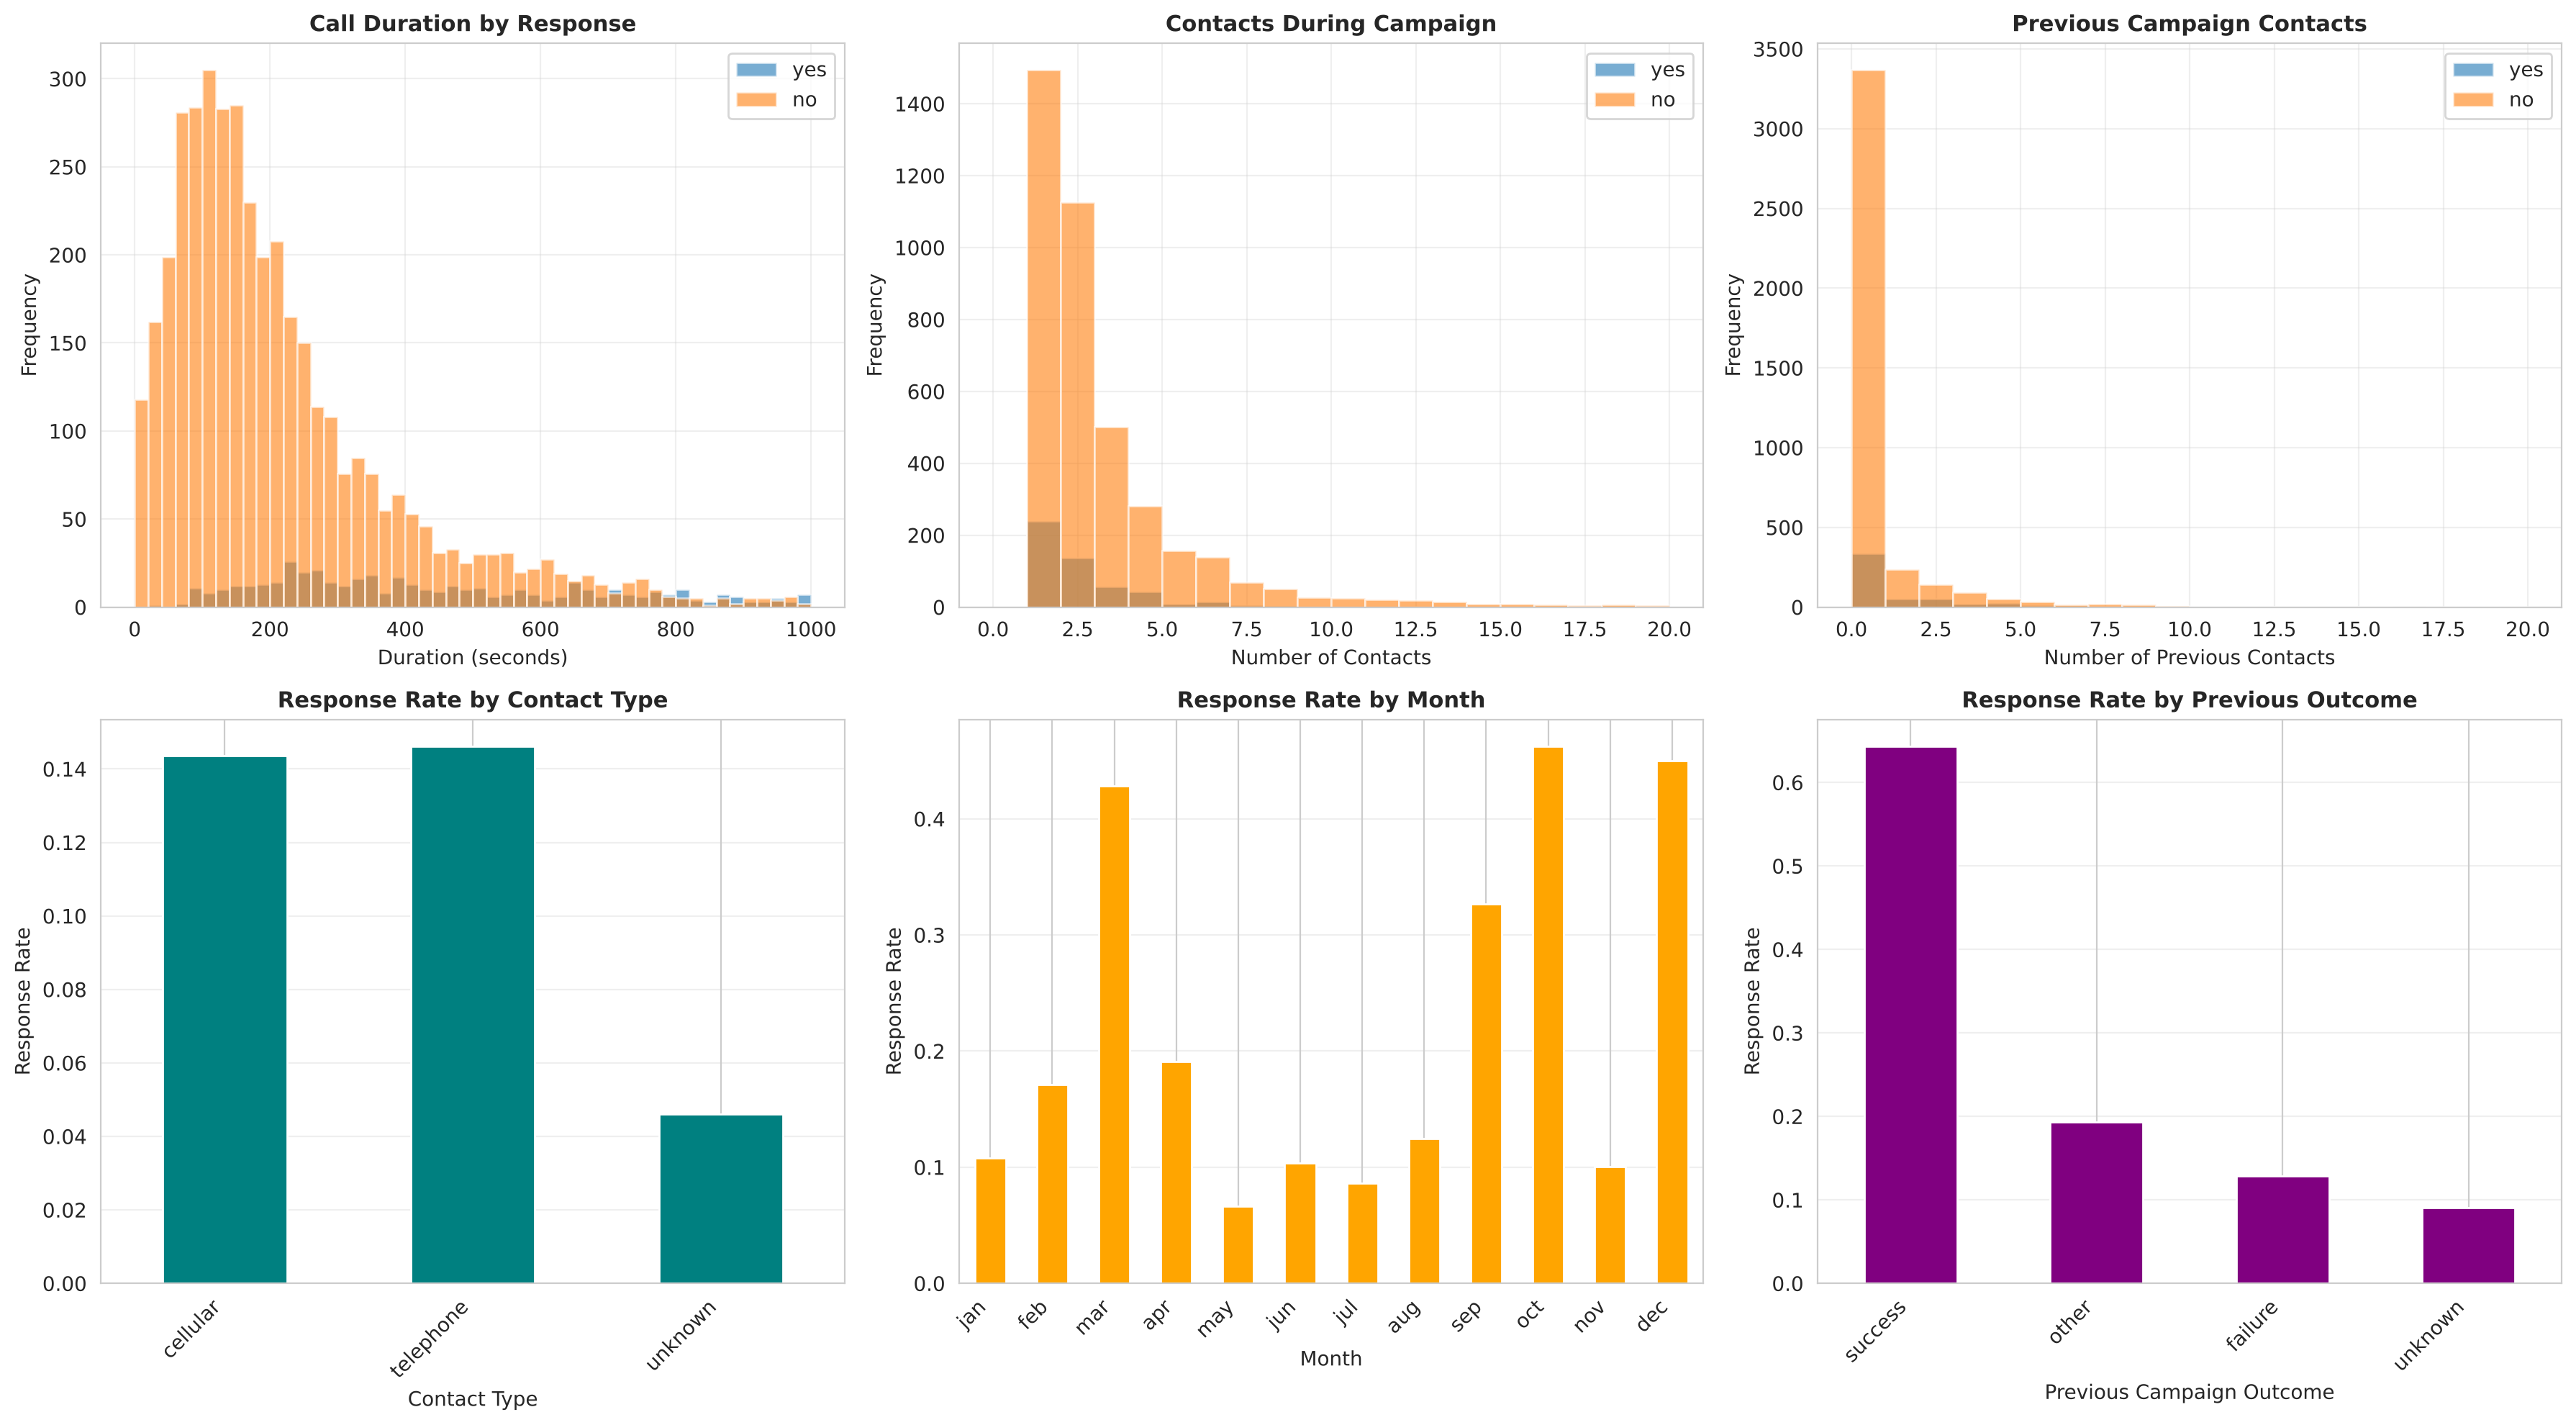


Call duration is strongly associated with a positive response (note: it is only known after the call).


In [6]:
print("="*70)
print("CAMPAIGN BEHAVIOR ANALYSIS")
print("="*70)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Contact Duration
ax = axes[0, 0]
for resp in ['yes', 'no']:
    df[df['y'] == resp]['duration'].hist(bins=50, alpha=0.6, label=resp, ax=ax, range=(0, 1000))
ax.set_title('Call Duration by Response', fontsize=11, fontweight='bold')
ax.set_xlabel('Duration (seconds)')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(alpha=0.3)

print(f"\n1. CALL DURATION:")
print(f"   Mean: {df['duration'].mean():.0f} seconds ({df['duration'].mean()/60:.1f} min)")
print(f"   Median: {df['duration'].median():.0f} seconds")
print(f"   Mean for 'yes': {df[df['y']=='yes']['duration'].mean():.0f} sec")
print(f"   Mean for 'no': {df[df['y']=='no']['duration'].mean():.0f} sec")

# 2. Number of Contacts (this campaign)
ax = axes[0, 1]
for resp in ['yes', 'no']:
    df[df['y'] == resp]['campaign'].hist(bins=20, alpha=0.6, label=resp, ax=ax, range=(0, 20))
ax.set_title('Contacts During Campaign', fontsize=11, fontweight='bold')
ax.set_xlabel('Number of Contacts')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(alpha=0.3)

print(f"\n2. CAMPAIGN CONTACTS:")
print(f"   Mean: {df['campaign'].mean():.1f}")
print(f"   Median: {df['campaign'].median():.0f}")
print(f"   Max: {df['campaign'].max()}")

# 3. Previous Contacts
ax = axes[0, 2]
for resp in ['yes', 'no']:
    df[df['y'] == resp]['previous'].hist(bins=20, alpha=0.6, label=resp, ax=ax, range=(0, 20))
ax.set_title('Previous Campaign Contacts', fontsize=11, fontweight='bold')
ax.set_xlabel('Number of Previous Contacts')
ax.set_ylabel('Frequency')
ax.legend()
ax.grid(alpha=0.3)

print(f"\n3. PREVIOUS CONTACTS:")
print(f"   Mean: {df['previous'].mean():.2f}")
print(f"   Never contacted: {(df['previous'] == 0).sum():,} ({100*(df['previous'] == 0).sum()/len(df):.1f}%)")

# 4. Contact Type
ax = axes[1, 0]
contact_response = df.groupby('contact')['y'].value_counts(normalize=True).unstack().fillna(0)
contact_response['yes'].plot(kind='bar', ax=ax, color='teal')
ax.set_title('Response Rate by Contact Type', fontsize=11, fontweight='bold')
ax.set_xlabel('Contact Type')
ax.set_ylabel('Response Rate')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.grid(alpha=0.3, axis='y')

print(f"\n4. CONTACT TYPE:")
for contact in df['contact'].unique():
    count = (df['contact'] == contact).sum()
    pct = 100 * count / len(df)
    print(f"   {contact}: {count:,} ({pct:.1f}%)")

# 5. Month
ax = axes[1, 1]
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
month_response = df.groupby('month')['y'].value_counts(normalize=True).unstack().fillna(0)
month_response = month_response.reindex([m for m in month_order if m in month_response.index])
month_response['yes'].plot(kind='bar', ax=ax, color='orange')
ax.set_title('Response Rate by Month', fontsize=11, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Response Rate')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.grid(alpha=0.3, axis='y')

print(f"\n5. CAMPAIGN MONTH:")
print(f"   Most contacts: {df['month'].value_counts().index[0]} ({df['month'].value_counts().values[0]:,})")

# 6. Previous Outcome
ax = axes[1, 2]
poutcome_response = df.groupby('poutcome')['y'].value_counts(normalize=True).unstack().fillna(0)
poutcome_response['yes'].sort_values(ascending=False).plot(kind='bar', ax=ax, color='purple')
ax.set_title('Response Rate by Previous Outcome', fontsize=11, fontweight='bold')
ax.set_xlabel('Previous Campaign Outcome')
ax.set_ylabel('Response Rate')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.grid(alpha=0.3, axis='y')

print(f"\n6. PREVIOUS OUTCOME:")
for outcome in df['poutcome'].unique():
    count = (df['poutcome'] == outcome).sum()
    pct = 100 * count / len(df)
    print(f"   {outcome}: {count:,} ({pct:.1f}%)")

plt.tight_layout()
plt.show()

print("\nCall duration is strongly associated with a positive response (note: it is only known after the call).")


## Correlation Analysis

CORRELATION ANALYSIS


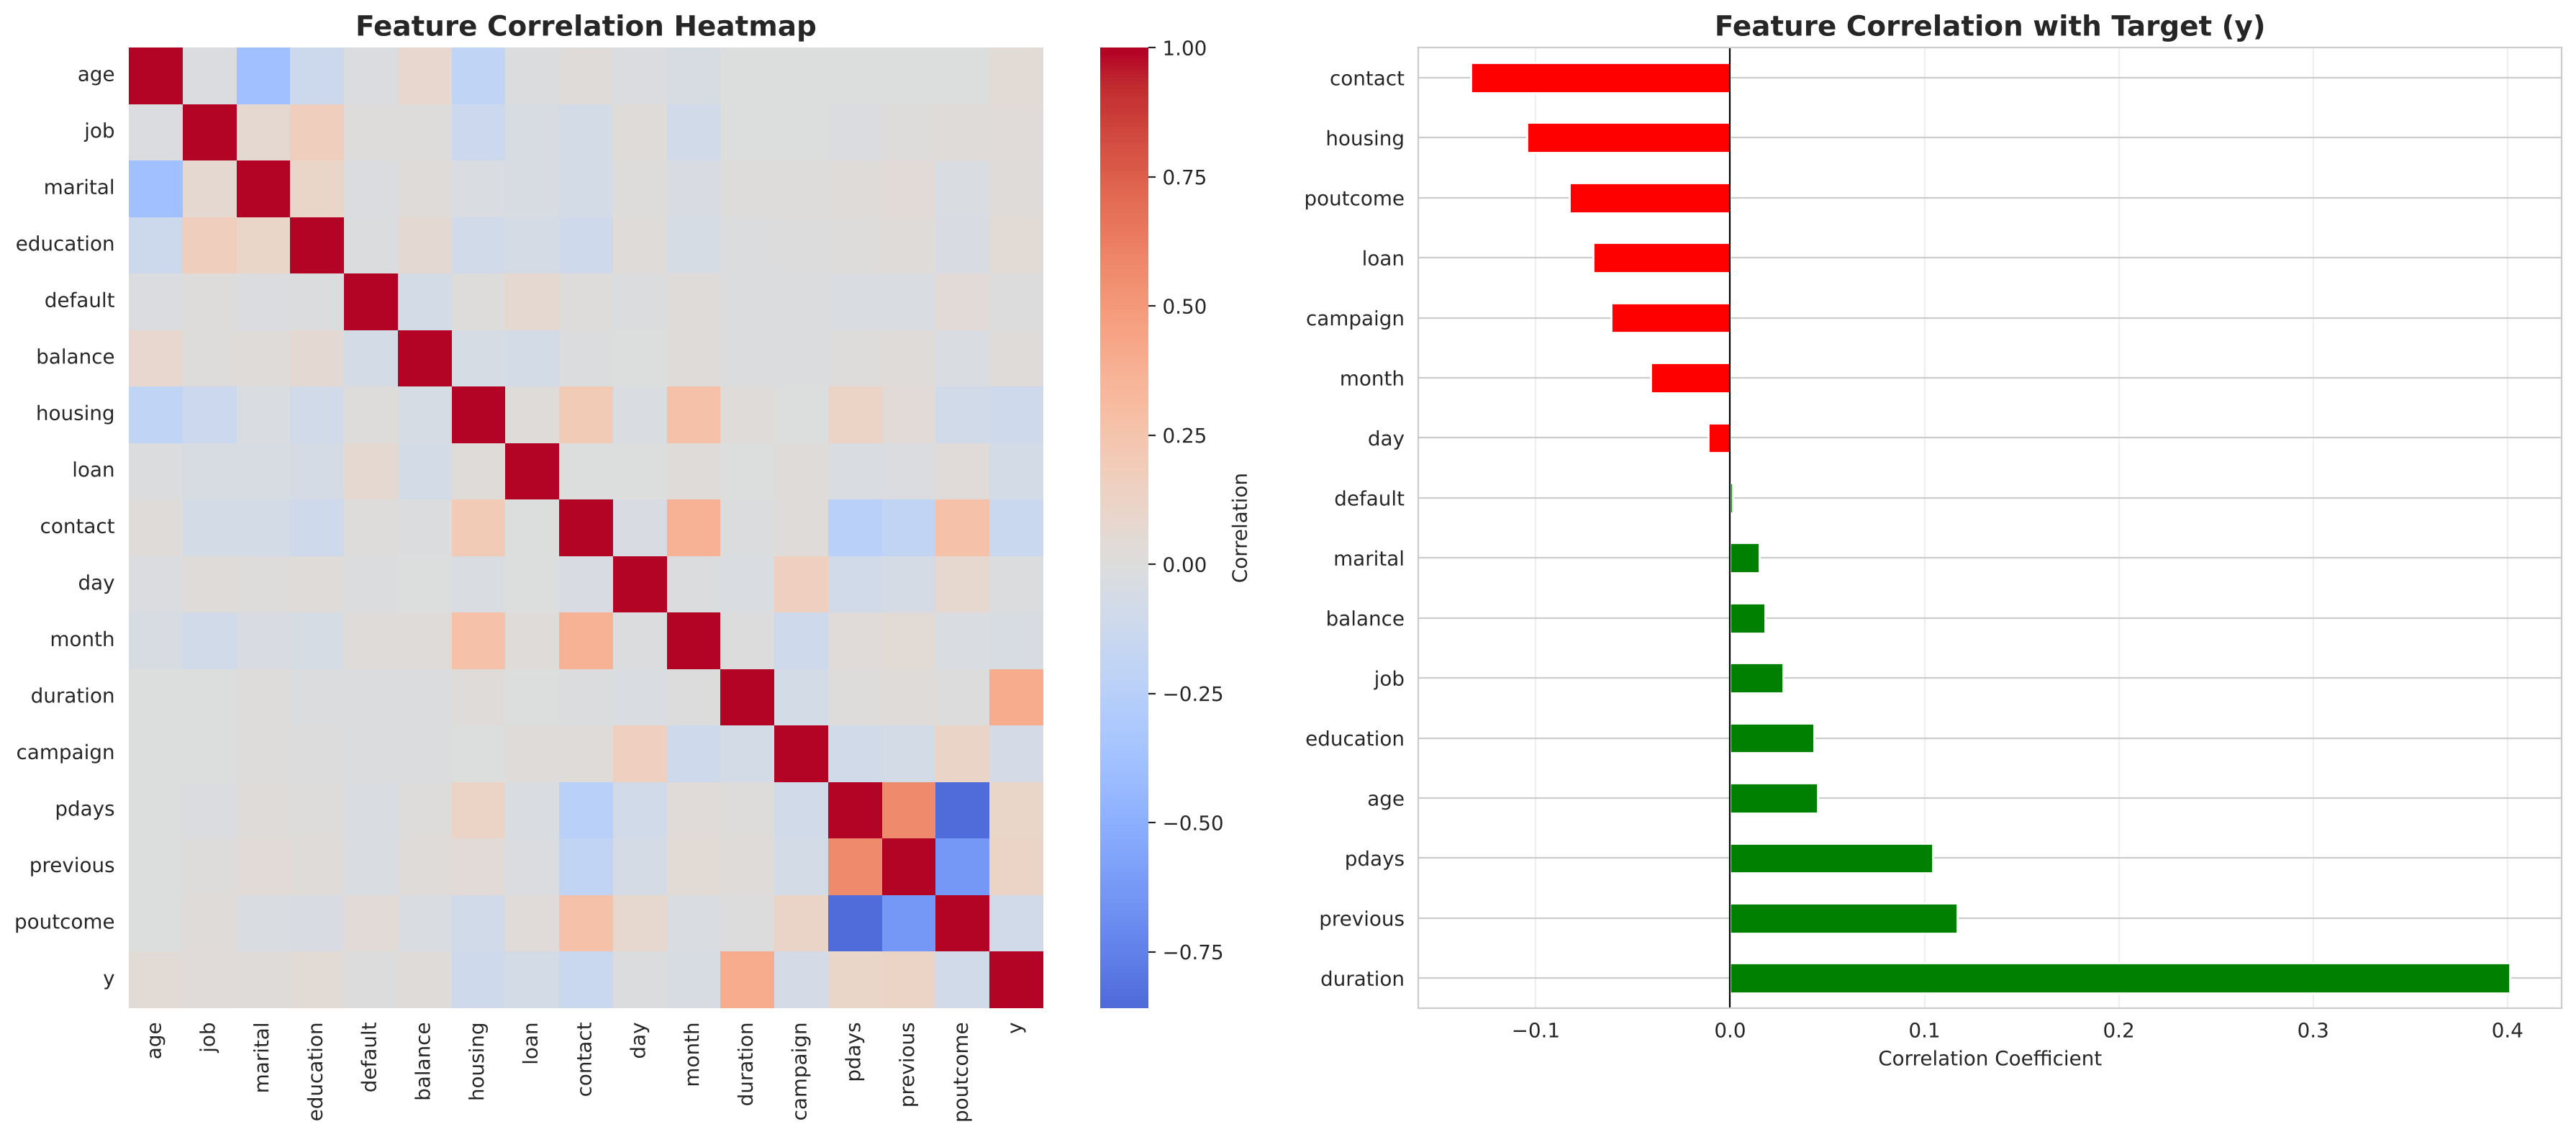


Top 5 Positive Correlations with Target:
   duration         0.401
   previous         0.117
   pdays            0.104
   age              0.045
   education        0.043

Top 5 Negative Correlations with Target:
   campaign        -0.061
   loan            -0.071
   poutcome        -0.083
   housing         -0.105
   contact         -0.134


In [7]:
print("="*70)
print("CORRELATION ANALYSIS")
print("="*70)

# Create a copy for encoding
df_corr = df.copy()

# Encode categorical variables for correlation
from sklearn.preprocessing import LabelEncoder

categorical_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'y']

for col in categorical_cols:
    le = LabelEncoder()
    df_corr[col] = le.fit_transform(df_corr[col])

# Calculate correlation matrix
corr_matrix = df_corr.corr()

# Plot heatmap
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Full correlation matrix
ax = axes[0]
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0, ax=ax, 
            cbar_kws={'label': 'Correlation'})
ax.set_title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')

# Correlation with target variable
ax = axes[1]
target_corr = corr_matrix['y'].drop('y').sort_values(ascending=False)
target_corr.plot(kind='barh', ax=ax, color=['green' if x > 0 else 'red' for x in target_corr])
ax.set_title('Feature Correlation with Target (y)', fontsize=14, fontweight='bold')
ax.set_xlabel('Correlation Coefficient')
ax.set_ylabel('')
ax.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
ax.grid(alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

print("\nTop 5 Positive Correlations with Target:")
for feat, corr in target_corr.head(5).items():
    print(f"   {feat:<15} {corr:>6.3f}")

print("\nTop 5 Negative Correlations with Target:")
for feat, corr in target_corr.tail(5).items():
    print(f"   {feat:<15} {corr:>6.3f}")


## Data Preprocessing - Encoding and Balancing

In [8]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import mlflow

print("="*70)
print("DATA PREPROCESSING")
print("="*70)

# Create working copy
df_model = df.copy()

print("\n1. Encoding Categorical Variables...")
# Encode categorical features
label_encoders = {}
categorical_features = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

for col in categorical_features:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    label_encoders[col] = le

print(f"   Encoded {len(categorical_features)} categorical features")

# Encode target
df_model['y'] = df_model['y'].map({'yes': 1, 'no': 0})
print("   Target variable encoded (yes=1, no=0)")

print("\n2. Handling Class Imbalance...")
print(f"   Original distribution:")
print(f"     - Class 0 (no):  {(df_model['y']==0).sum():,}")
print(f"     - Class 1 (yes): {(df_model['y']==1).sum():,}")
print(f"     - Imbalance ratio: {(df_model['y']==0).sum() / (df_model['y']==1).sum():.1f}:1")

# Balance using undersampling
yes_indices = df_model[df_model['y'] == 1].index
no_indices = df_model[df_model['y'] == 0].index

np.random.seed(42)
no_indices_sampled = np.random.choice(no_indices, size=len(yes_indices), replace=False)

balanced_indices = np.concatenate([yes_indices, no_indices_sampled])
np.random.shuffle(balanced_indices)

df_balanced = df_model.loc[balanced_indices]

print(f"\n   Balanced distribution:")
print(f"     - Class 0 (no):  {(df_balanced['y']==0).sum():,}")
print(f"     - Class 1 (yes): {(df_balanced['y']==1).sum():,}")
print(f"     - Balance ratio: 1:1")

print("\n3. Train-Test Split...")
# Separate features and target
X = df_balanced.drop('y', axis=1)
y = df_balanced['y']

# Split data (80-20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"   Training samples: {len(X_train):,} ({len(X_train)/len(X)*100:.1f}%)")
print(f"   Test samples:     {len(X_test):,} ({len(X_test)/len(X)*100:.1f}%)")
print(f"   Features:         {X.shape[1]}")

print("\nPreprocessing complete.")
print("="*70)


DATA PREPROCESSING

1. Encoding Categorical Variables...
   Encoded 9 categorical features
   Target variable encoded (yes=1, no=0)

2. Handling Class Imbalance...
   Original distribution:
     - Class 0 (no):  4,000
     - Class 1 (yes): 521
     - Imbalance ratio: 7.7:1

   Balanced distribution:
     - Class 0 (no):  521
     - Class 1 (yes): 521
     - Balance ratio: 1:1

3. Train-Test Split...
   Training samples: 833 (79.9%)
   Test samples:     209 (20.1%)
   Features:         16

Preprocessing complete.


## Feature Scaling

In [9]:
from sklearn.preprocessing import StandardScaler

print("="*70)
print("FEATURE SCALING")
print("="*70)

print("\nApplying StandardScaler to normalize features...")

# Initialize scaler
scaler = StandardScaler()

# Fit on training data and transform both sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTraining data scaled: {X_train_scaled.shape}")
print(f"Test data scaled: {X_test_scaled.shape}")

print("\nSample statistics (before scaling):")
print(X_train.describe().loc[['mean', 'std']].round(2))

print("\nSample statistics (after scaling):")
print(pd.DataFrame(X_train_scaled, columns=X_train.columns).describe().loc[['mean', 'std']].round(2))

print("\nFeatures now have mean 0 and standard deviation 1.")
print("="*70)


FEATURE SCALING

Applying StandardScaler to normalize features...

Training data scaled: (833, 16)
Test data scaled: (209, 16)

Sample statistics (before scaling):
        age   job  marital  education  default  balance  housing  loan  \
mean  41.57  4.39     1.16       1.26     0.01  1475.74     0.51  0.12   
std   11.77  3.23     0.62       0.75     0.12  2611.84     0.50  0.32   

      contact    day  month  duration  campaign   pdays  previous  poutcome  
mean     0.50  16.04   5.41    392.64      2.56   51.32      0.75      2.47  
std      0.82   8.30   3.19    363.19      3.13  107.26      1.75      1.02  

Sample statistics (after scaling):
      age  job  marital  education  default  balance  housing  loan  contact  \
mean  0.0  0.0      0.0        0.0     -0.0     -0.0      0.0   0.0      0.0   
std   1.0  1.0      1.0        1.0      1.0      1.0      1.0   1.0      1.0   

      day  month  duration  campaign  pdays  previous  poutcome  
mean  0.0    0.0       0.0      -0.0

## Model Training - Multiple Algorithms

In [10]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import time

print("="*70)
print("MODEL TRAINING & COMPARISON")
print("="*70)

# Set MLflow experiment
mlflow.set_experiment("bank-marketing-prediction")

# Define models to train
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, max_depth=5, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine': SVC(kernel='rbf', probability=True, random_state=42)
}

results = []

for model_name, model in models.items():
    print(f"\n{'='*70}")
    print(f"Training: {model_name}")
    print(f"{'='*70}")
    
    with mlflow.start_run(run_name=f"{model_name} - Balanced & Scaled"):
        # Log parameters
        mlflow.log_param("model_type", model_name)
        mlflow.log_param("data_balancing", "undersampling")
        mlflow.log_param("feature_scaling", "StandardScaler")
        mlflow.log_param("train_size", len(X_train))
        mlflow.log_param("test_size", len(X_test))
        
        # Train model
        start_time = time.time()
        model.fit(X_train_scaled, y_train)
        training_time = time.time() - start_time
        
        # Make predictions
        y_pred = model.predict(X_test_scaled)
        y_pred_proba = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, 'predict_proba') else None
        
        # Calculate metrics
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        roc_auc = roc_auc_score(y_test, y_pred_proba) if y_pred_proba is not None else None
        
        # Log metrics
        mlflow.log_metric("accuracy", accuracy)
        mlflow.log_metric("precision", precision)
        mlflow.log_metric("recall", recall)
        mlflow.log_metric("f1_score", f1)
        if roc_auc:
            mlflow.log_metric("roc_auc", roc_auc)
        mlflow.log_metric("training_time", training_time)
        
        # Log model
        mlflow.sklearn.log_model(model, f"{model_name.lower().replace(' ', '_')}_model")
        
        # Store results
        results.append({
            'Model': model_name,
            'Accuracy': accuracy,
            'Precision': precision,
            'Recall': recall,
            'F1 Score': f1,
            'ROC-AUC': roc_auc if roc_auc else 0,
            'Training Time (s)': training_time
        })
        
        print(f"   Accuracy:  {accuracy:.4f}")
        print(f"   Precision: {precision:.4f}")
        print(f"   Recall:    {recall:.4f}")
        print(f"   F1 Score:  {f1:.4f}")
        if roc_auc:
            print(f"   ROC-AUC:   {roc_auc:.4f}")
        print(f"   Time:      {training_time:.2f}s")

print("\n" + "="*70)
print("All models trained.")
print("="*70)


MODEL TRAINING & COMPARISON

Training: Logistic Regression


   Accuracy:  0.7608
   Precision: 0.7500
   Recall:    0.7788
   F1 Score:  0.7642
   ROC-AUC:   0.8530
   Time:      0.01s

Training: Random Forest


   Accuracy:  0.8230
   Precision: 0.8018
   Recall:    0.8558
   F1 Score:  0.8279
   ROC-AUC:   0.9239
   Time:      0.17s

Training: Gradient Boosting


   Accuracy:  0.8373
   Precision: 0.8365
   Recall:    0.8365
   F1 Score:  0.8365
   ROC-AUC:   0.9107
   Time:      0.20s

Training: K-Nearest Neighbors


   Accuracy:  0.6938
   Precision: 0.7222
   Recall:    0.6250
   F1 Score:  0.6701
   ROC-AUC:   0.7643
   Time:      0.00s

Training: Support Vector Machine


   Accuracy:  0.7560
   Precision: 0.7677
   Recall:    0.7308
   F1 Score:  0.7488
   ROC-AUC:   0.8609
   Time:      0.05s

All models trained.


## Model Performance Comparison

MODEL PERFORMANCE COMPARISON


                 Model  Accuracy  Precision   Recall  F1 Score  ROC-AUC  Training Time (s)
   Logistic Regression  0.760766   0.750000 0.778846  0.764151 0.853022           0.007401
         Random Forest  0.822967   0.801802 0.855769  0.827907 0.923901           0.174334
     Gradient Boosting  0.837321   0.836538 0.836538  0.836538 0.910714           0.203357
   K-Nearest Neighbors  0.693780   0.722222 0.625000  0.670103 0.764332           0.002267
Support Vector Machine  0.755981   0.767677 0.730769  0.748768 0.860897           0.049739


Best model: Gradient Boosting
   F1 Score: 0.8365


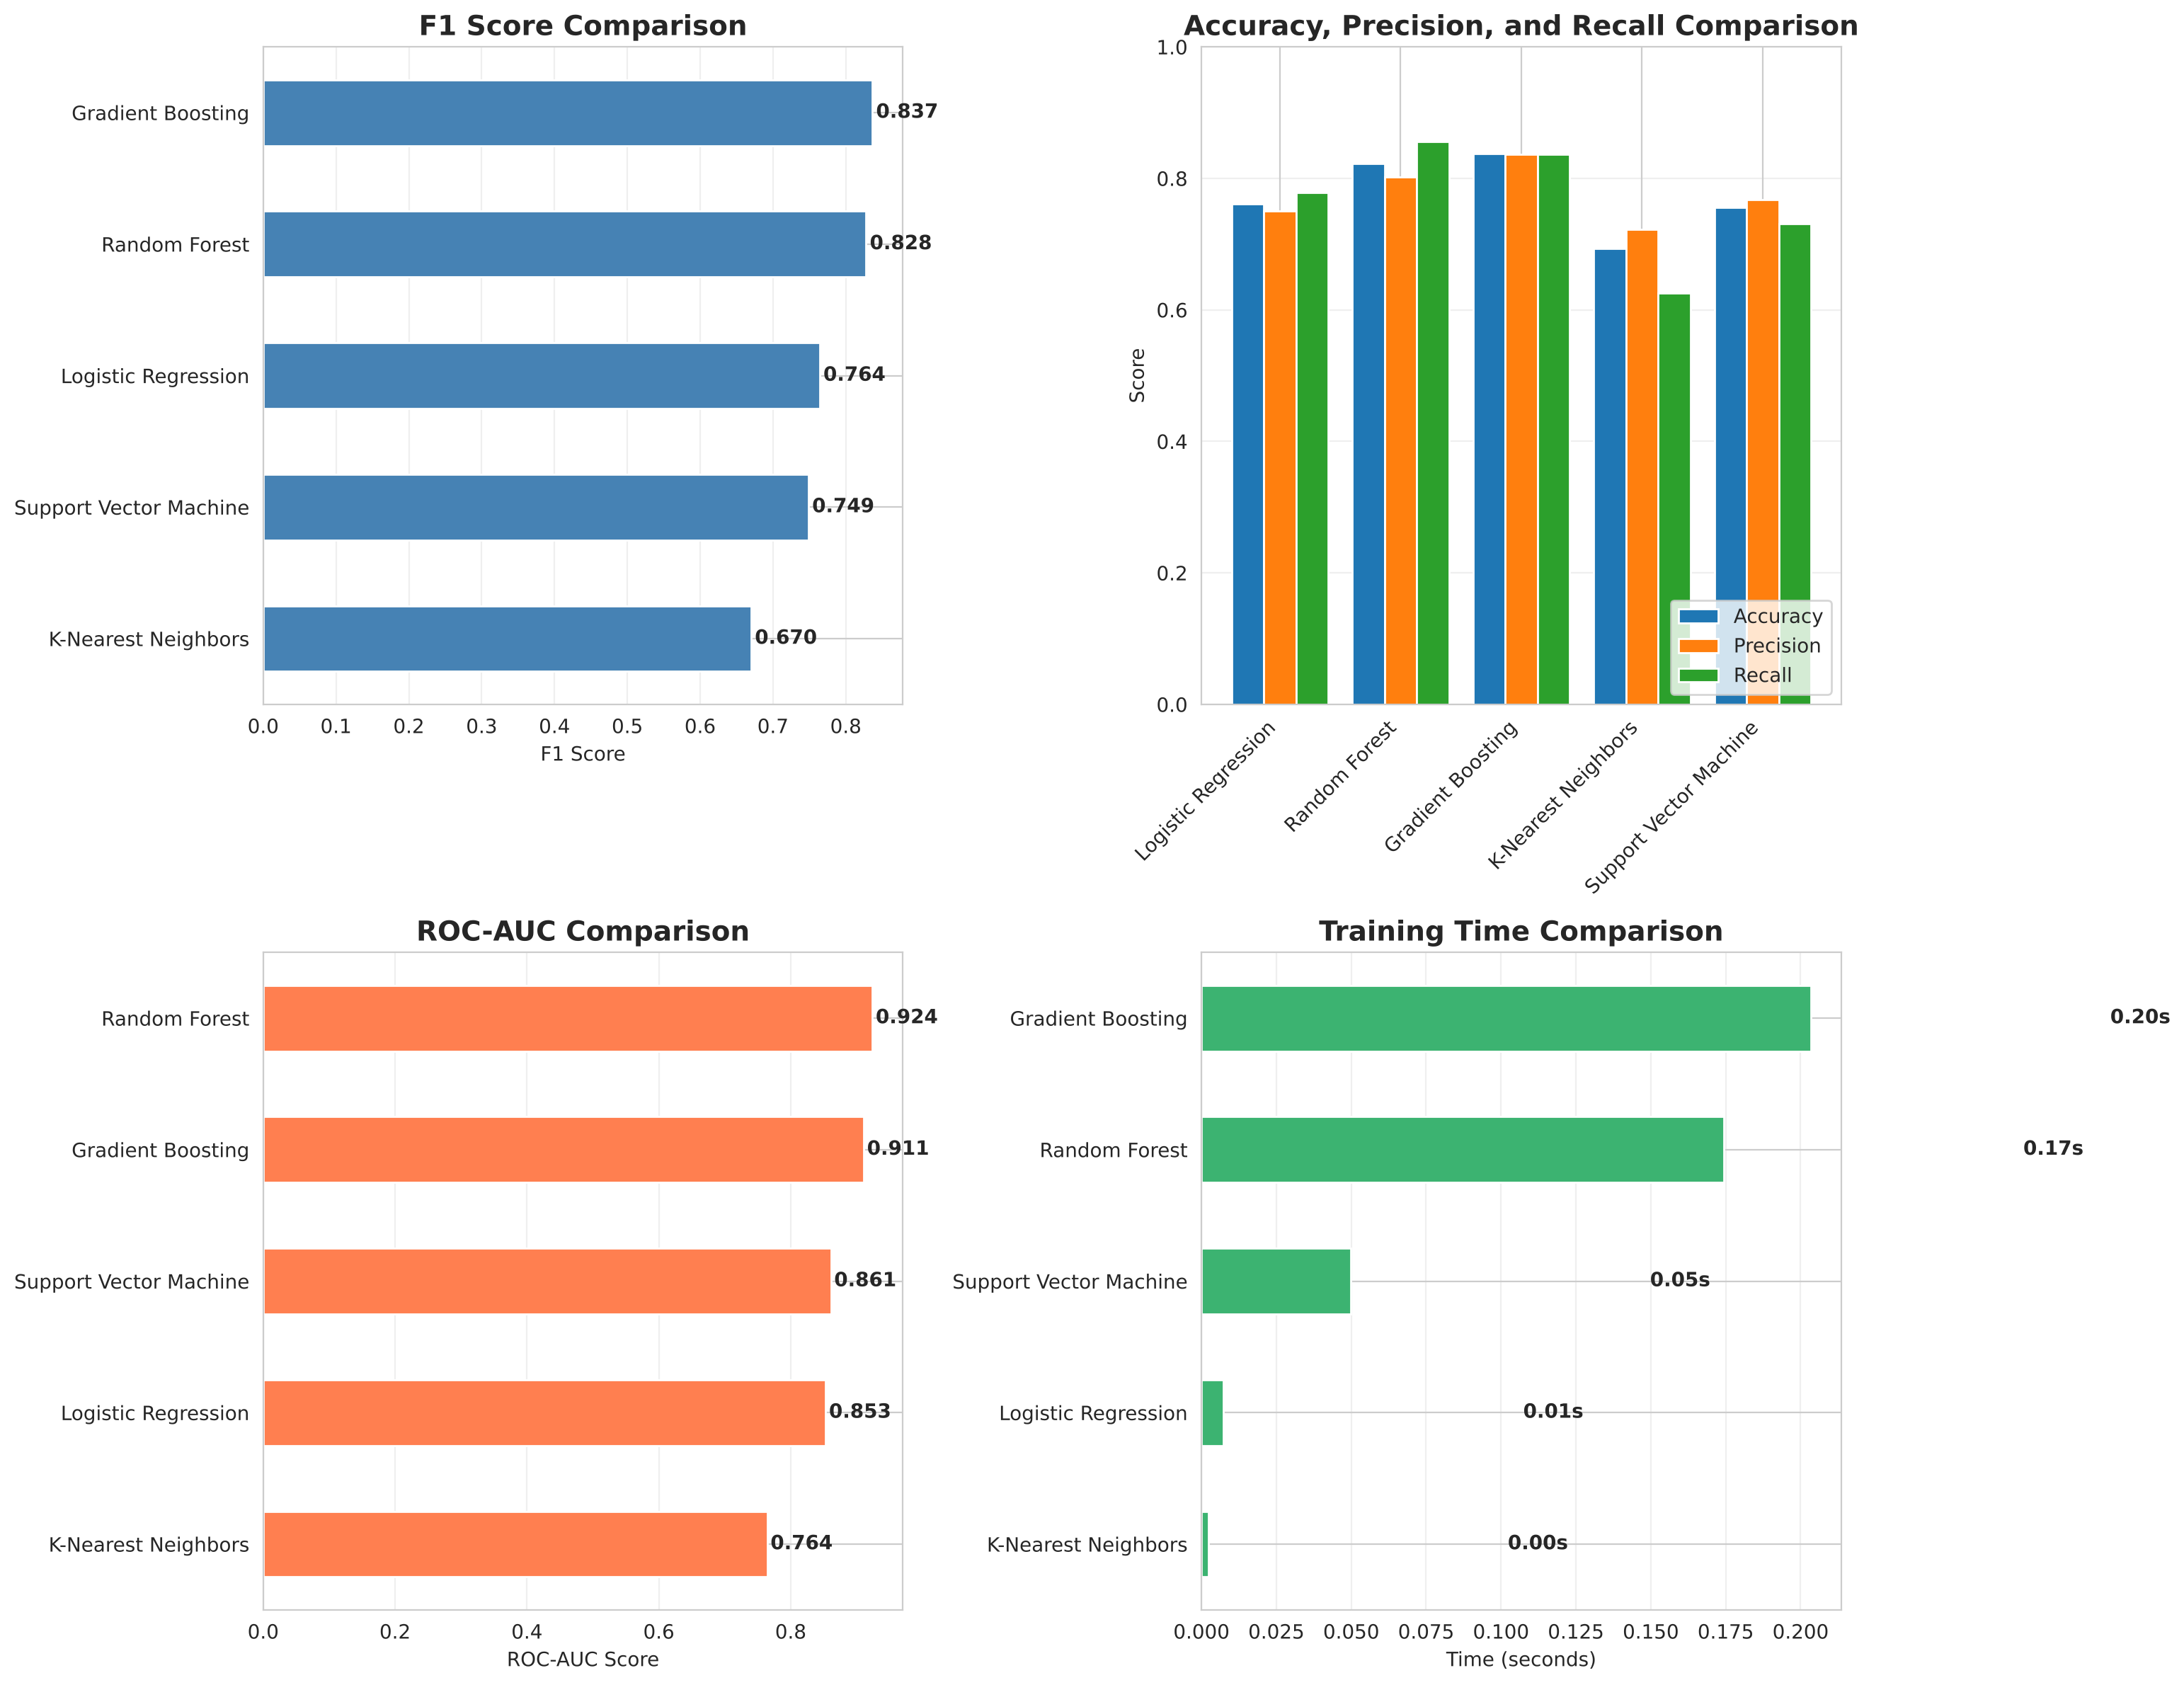

In [11]:
# Create results dataframe
results_df = pd.DataFrame(results)

print("="*70)
print("MODEL PERFORMANCE COMPARISON")
print("="*70)
print("\n")
print(results_df.to_string(index=False))

# Find best model
best_model_idx = results_df['F1 Score'].idxmax()
best_model_name = results_df.loc[best_model_idx, 'Model']
best_f1 = results_df.loc[best_model_idx, 'F1 Score']

print(f"\n\nBest model: {best_model_name}")
print(f"   F1 Score: {best_f1:.4f}")
print("="*70)

# Visualize comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. F1 Score Comparison
ax = axes[0, 0]
results_df.sort_values('F1 Score', ascending=True).plot(
    x='Model', y='F1 Score', kind='barh', ax=ax, legend=False, color='steelblue'
)
ax.set_title('F1 Score Comparison', fontsize=14, fontweight='bold')
ax.set_xlabel('F1 Score')
ax.set_ylabel('')
ax.grid(alpha=0.3, axis='x')
for i, v in enumerate(results_df.sort_values('F1 Score')['F1 Score']):
    ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontweight='bold')

# 2. Accuracy vs Precision vs Recall
ax = axes[0, 1]
metrics_df = results_df.set_index('Model')[['Accuracy', 'Precision', 'Recall']]
metrics_df.plot(kind='bar', ax=ax, width=0.8)
ax.set_title('Accuracy, Precision, and Recall Comparison', fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.set_xlabel('')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
ax.legend(loc='lower right')
ax.grid(alpha=0.3, axis='y')
ax.set_ylim([0, 1])

# 3. ROC-AUC Comparison
ax = axes[1, 0]
results_df_roc = results_df[results_df['ROC-AUC'] > 0].sort_values('ROC-AUC', ascending=True)
results_df_roc.plot(x='Model', y='ROC-AUC', kind='barh', ax=ax, legend=False, color='coral')
ax.set_title('ROC-AUC Comparison', fontsize=14, fontweight='bold')
ax.set_xlabel('ROC-AUC Score')
ax.set_ylabel('')
ax.grid(alpha=0.3, axis='x')
for i, v in enumerate(results_df_roc['ROC-AUC']):
    ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontweight='bold')

# 4. Training Time
ax = axes[1, 1]
results_df.sort_values('Training Time (s)', ascending=True).plot(
    x='Model', y='Training Time (s)', kind='barh', ax=ax, legend=False, color='mediumseagreen'
)
ax.set_title('Training Time Comparison', fontsize=14, fontweight='bold')
ax.set_xlabel('Time (seconds)')
ax.set_ylabel('')
ax.grid(alpha=0.3, axis='x')
for i, v in enumerate(results_df.sort_values('Training Time (s)')['Training Time (s)']):
    ax.text(v + 0.1, i, f'{v:.2f}s', va='center', fontweight='bold')

plt.tight_layout()
plt.show()


## Best Model - Detailed Evaluation

DETAILED EVALUATION: GRADIENT BOOSTING

1. Classification Report:
              precision    recall  f1-score   support

No Subscribe       0.84      0.84      0.84       105
   Subscribe       0.84      0.84      0.84       104

    accuracy                           0.84       209
   macro avg       0.84      0.84      0.84       209
weighted avg       0.84      0.84      0.84       209



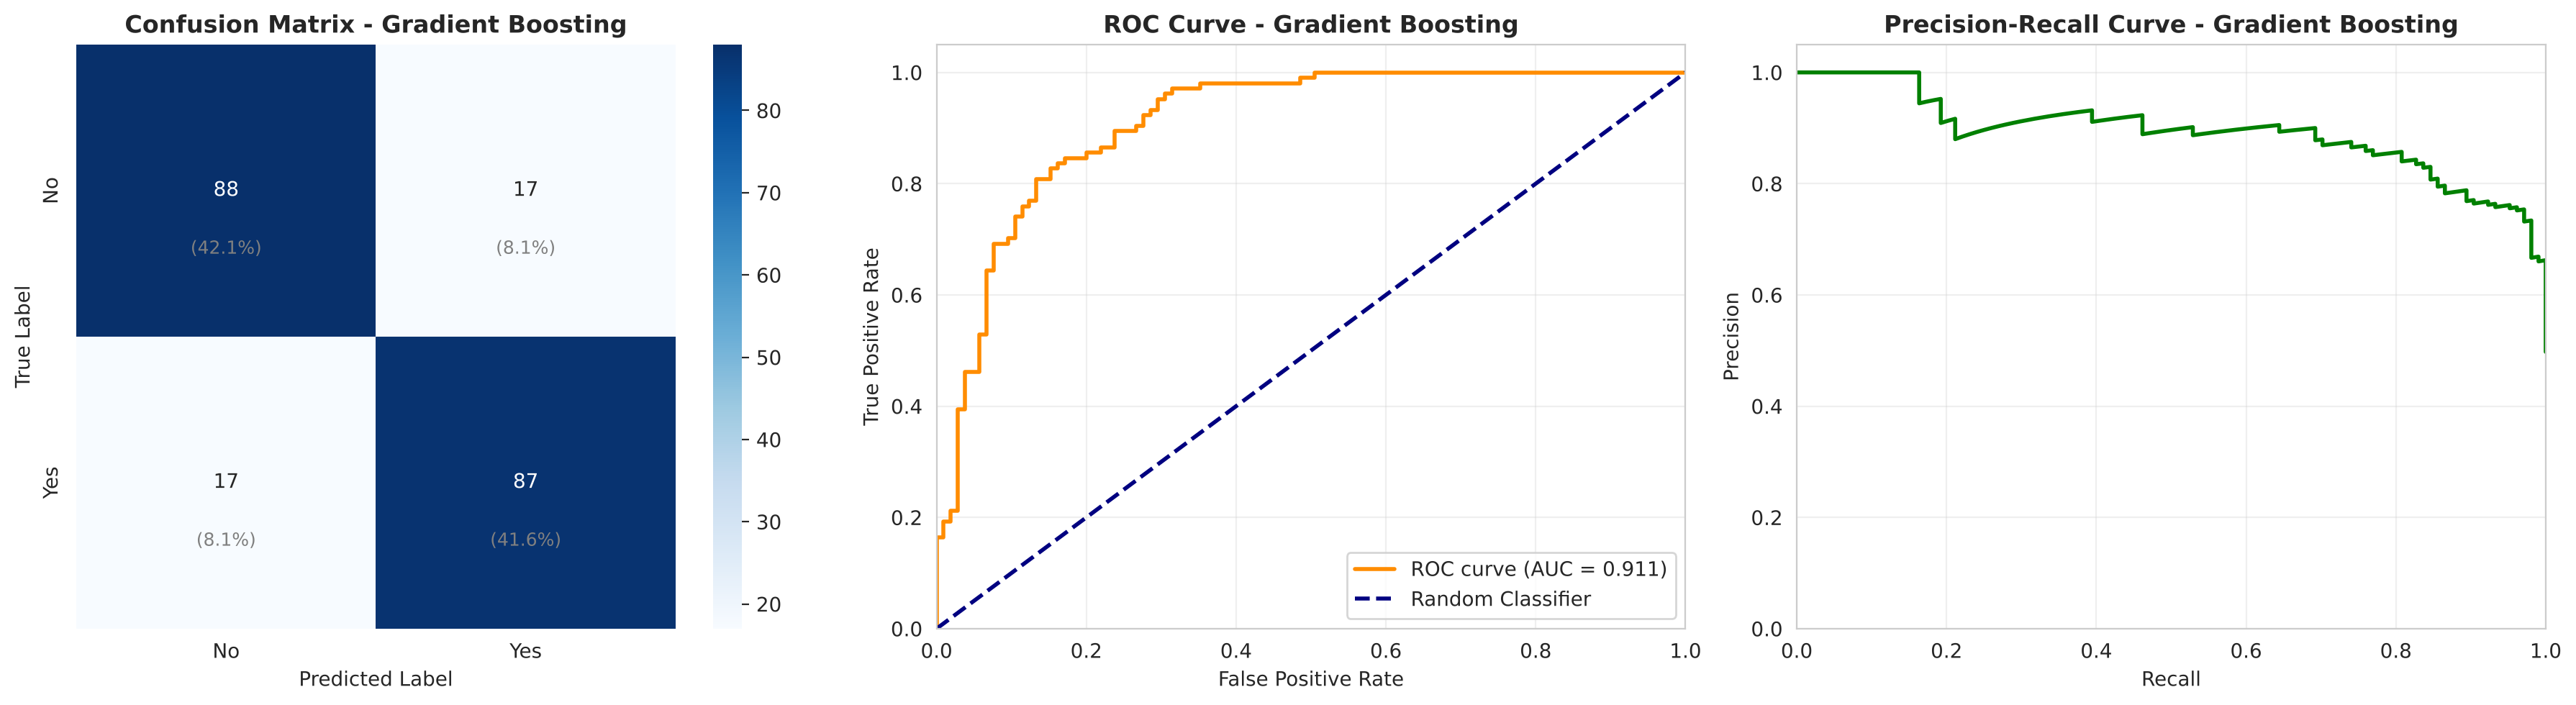


2. Confusion Matrix Interpretation:
   True Negatives:    88 (Correctly predicted 'No')
   False Positives:   17 (Incorrectly predicted 'Yes')
   False Negatives:   17 (Incorrectly predicted 'No')
   True Positives:    87 (Correctly predicted 'Yes')

3. Business Metrics:
   Conversion Accuracy: 83.7% (caught 87 of 104 actual subscribers)
   Campaign Efficiency: 83.7% (87 subscribers from 104 targeted)
   Cost Savings: 83.8% (avoided 88 of 105 non-subscribers)


In [12]:
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

# Get the best model
best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test_scaled)
y_pred_proba_best = best_model.predict_proba(X_test_scaled)[:, 1]

print("="*70)
print(f"DETAILED EVALUATION: {best_model_name.upper()}")
print("="*70)

# Classification Report
print("\n1. Classification Report:")
print(classification_report(y_test, y_pred_best, target_names=['No Subscribe', 'Subscribe']))

# Confusion Matrix
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Confusion Matrix
ax = axes[0]
cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, 
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
ax.set_title(f'Confusion Matrix - {best_model_name}', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label')
ax.set_xlabel('Predicted Label')

# Add percentages
for i in range(2):
    for j in range(2):
        pct = cm[i, j] / cm.sum() * 100
        ax.text(j + 0.5, i + 0.7, f'({pct:.1f}%)', ha='center', va='center', fontsize=9, color='gray')

# 2. ROC Curve
ax = axes[1]
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba_best)
roc_auc_best = auc(fpr, tpr)

ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc_best:.3f})')
ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title(f'ROC Curve - {best_model_name}', fontsize=12, fontweight='bold')
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

# 3. Precision-Recall Trade-off
ax = axes[2]
from sklearn.metrics import precision_recall_curve
precision_curve, recall_curve, thresholds_pr = precision_recall_curve(y_test, y_pred_proba_best)

ax.plot(recall_curve, precision_curve, color='green', lw=2)
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title(f'Precision-Recall Curve - {best_model_name}', fontsize=12, fontweight='bold')
ax.grid(alpha=0.3)
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])

plt.tight_layout()
plt.show()

print("\n2. Confusion Matrix Interpretation:")
tn, fp, fn, tp = cm.ravel()
print(f"   True Negatives:  {tn:>4} (Correctly predicted 'No')")
print(f"   False Positives: {fp:>4} (Incorrectly predicted 'Yes')")
print(f"   False Negatives: {fn:>4} (Incorrectly predicted 'No')")
print(f"   True Positives:  {tp:>4} (Correctly predicted 'Yes')")

print("\n3. Business Metrics:")
print(f"   Conversion Accuracy: {tp/(tp+fn)*100:.1f}% (caught {tp} of {tp+fn} actual subscribers)")
print(f"   Campaign Efficiency: {tp/(tp+fp)*100:.1f}% ({tp} subscribers from {tp+fp} targeted)")
print(f"   Cost Savings: {tn/(tn+fp)*100:.1f}% (avoided {tn} of {tn+fp} non-subscribers)")


## Feature Importance Analysis

FEATURE IMPORTANCE ANALYSIS

Top 10 Most Important Features:
 Feature  Importance
duration    0.448433
 balance    0.101222
   month    0.069866
 contact    0.068121
     day    0.056632
     age    0.054489
   pdays    0.043079
 housing    0.029997
previous    0.027054
poutcome    0.025608


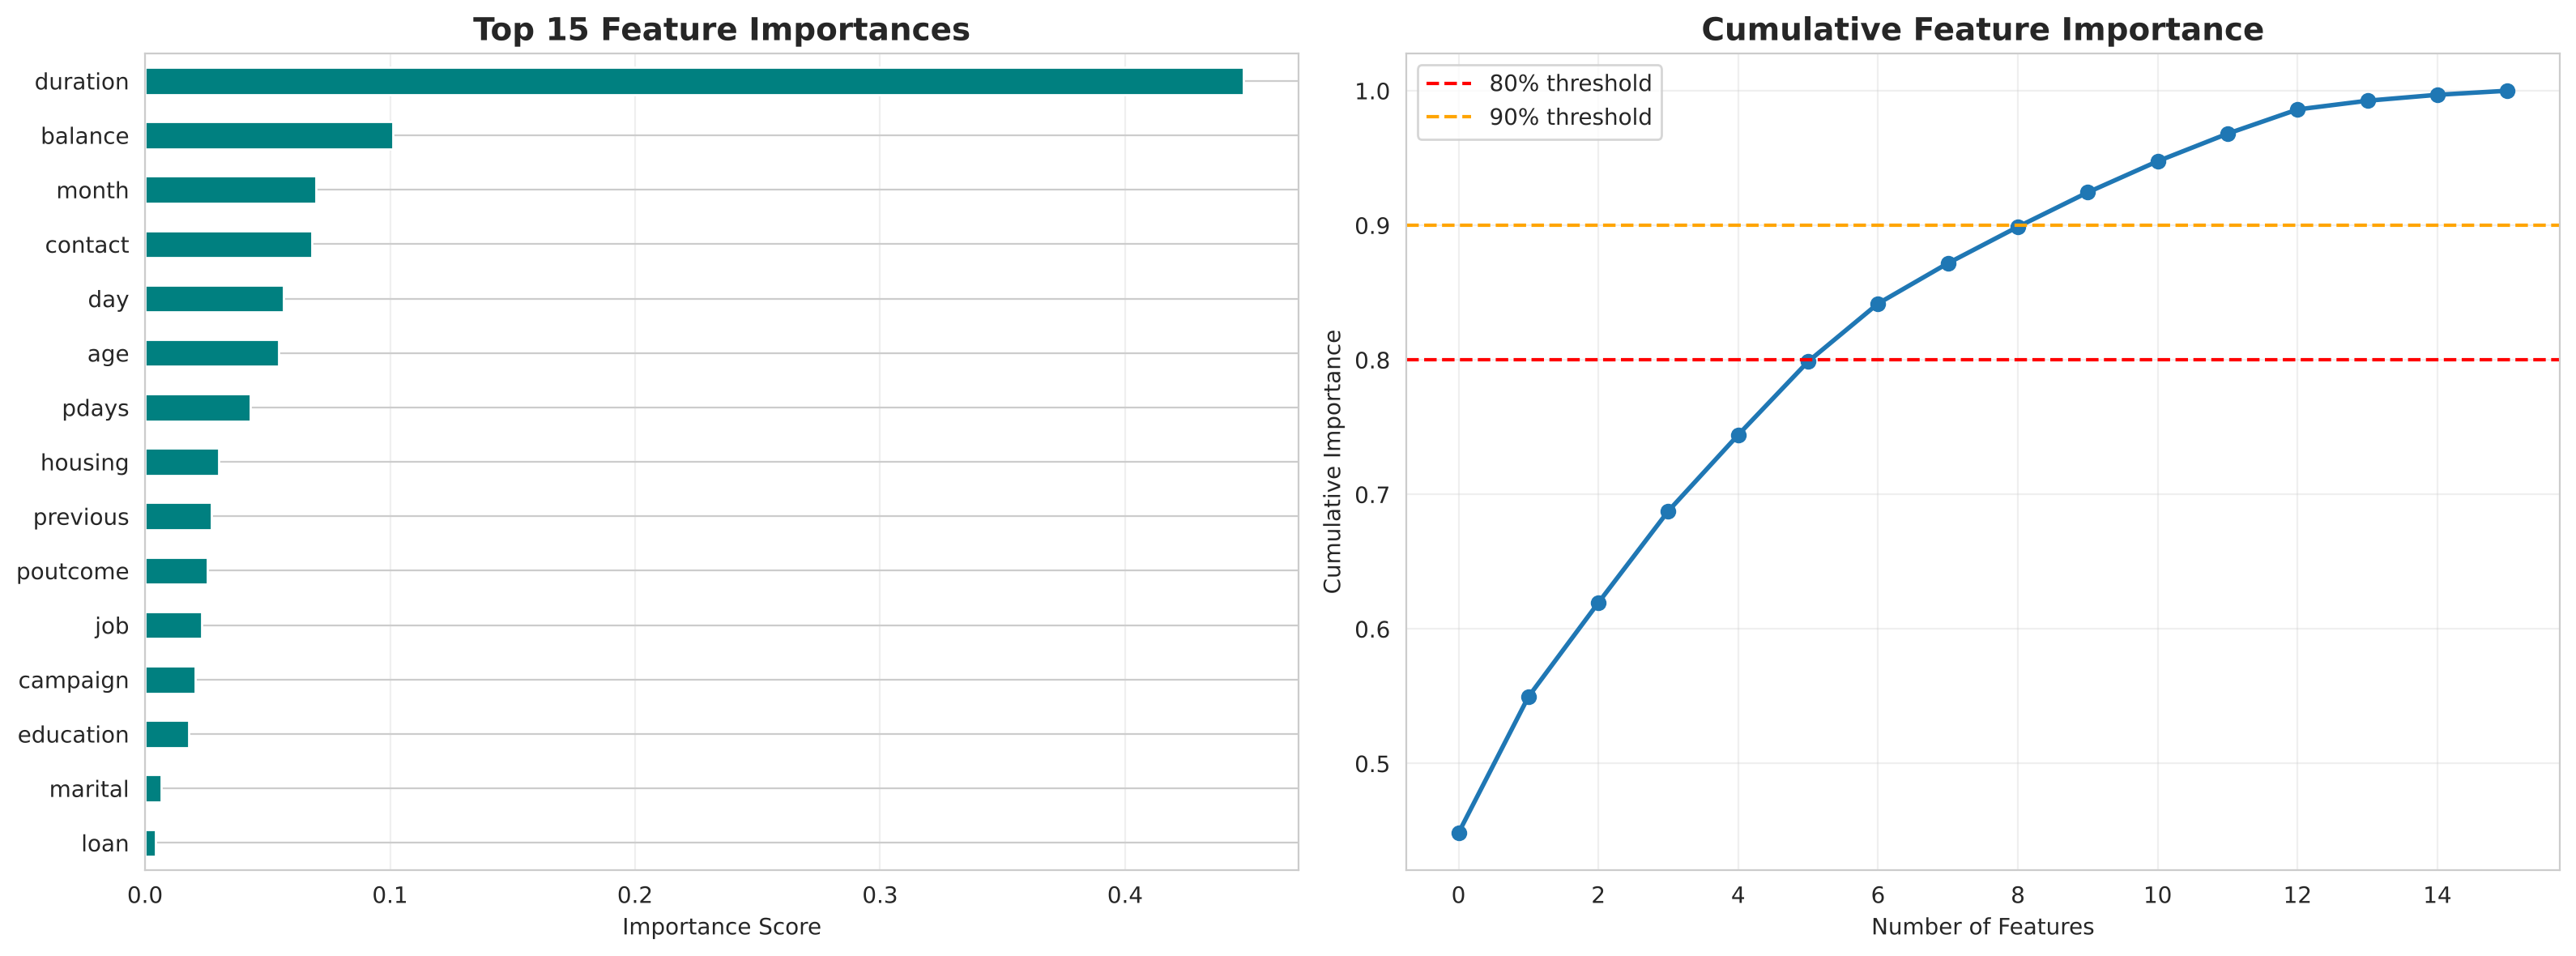


The top 7 features account for 80% of total importance.


In [13]:
# Feature importance (if available)
if hasattr(best_model, 'feature_importances_'):
    print("="*70)
    print("FEATURE IMPORTANCE ANALYSIS")
    print("="*70)
    
    # Get feature importances
    feature_importance = pd.DataFrame({
        'Feature': X.columns,
        'Importance': best_model.feature_importances_
    }).sort_values('Importance', ascending=False)
    
    print("\nTop 10 Most Important Features:")
    print(feature_importance.head(10).to_string(index=False))
    
    # Visualize
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Top 15 features
    ax = axes[0]
    top_features = feature_importance.head(15)
    top_features.plot(x='Feature', y='Importance', kind='barh', ax=ax, legend=False, color='teal')
    ax.set_title('Top 15 Feature Importances', fontsize=14, fontweight='bold')
    ax.set_xlabel('Importance Score')
    ax.set_ylabel('')
    ax.invert_yaxis()
    ax.grid(alpha=0.3, axis='x')
    
    # Cumulative importance
    ax = axes[1]
    feature_importance['Cumulative'] = feature_importance['Importance'].cumsum()
    ax.plot(range(len(feature_importance)), feature_importance['Cumulative'], marker='o', linewidth=2)
    ax.axhline(y=0.8, color='red', linestyle='--', label='80% threshold')
    ax.axhline(y=0.9, color='orange', linestyle='--', label='90% threshold')
    ax.set_title('Cumulative Feature Importance', fontsize=14, fontweight='bold')
    ax.set_xlabel('Number of Features')
    ax.set_ylabel('Cumulative Importance')
    ax.legend()
    ax.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Find how many features needed for 80% importance
    n_features_80 = (feature_importance['Cumulative'] <= 0.8).sum() + 1
    print(f"\nThe top {n_features_80} features account for 80% of total importance.")
    
elif hasattr(best_model, 'coef_'):
    print("="*70)
    print("FEATURE COEFFICIENTS ANALYSIS (LOGISTIC REGRESSION)")
    print("="*70)
    
    # Get coefficients
    feature_coef = pd.DataFrame({
        'Feature': X.columns,
        'Coefficient': best_model.coef_[0]
    }).sort_values('Coefficient', key=abs, ascending=False)
    
    print("\nTop 10 Most Influential Features:")
    print(feature_coef.head(10).to_string(index=False))
    
    # Visualize
    plt.figure(figsize=(12, 8))
    top_coef = feature_coef.head(15)
    colors = ['green' if x > 0 else 'red' for x in top_coef['Coefficient']]
    plt.barh(range(len(top_coef)), top_coef['Coefficient'], color=colors)
    plt.yticks(range(len(top_coef)), top_coef['Feature'])
    plt.xlabel('Coefficient Value')
    plt.title('Top 15 Feature Coefficients (Logistic Regression)', fontsize=14, fontweight='bold')
    plt.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
    plt.grid(alpha=0.3, axis='x')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
    
    print("\nPositive coefficients increase subscription probability.")
    print("   Negative coefficients decrease subscription probability")

else:
    print("\nFeature importance is not available for this model type.")


## Business Insights & Recommendations